Mehrdad Mohammadian

In [1]:
import json
import shap
import numpy as np
import pandas as pd
import seaborn as sns
from openai import OpenAI
from textwrap import fill
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from xgboost import XGBClassifier
from scipy.stats import chi2_contingency
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import (TunedThresholdClassifierCV,
                                    cross_val_score, train_test_split, 
                                    StratifiedKFold, GridSearchCV)
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, auc, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score, make_scorer)

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False})

/home/mehrdad/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data cleaning and EDA

**!!! WAIT !!!**

I found something very important about this dataset. Its documentation contains several errors. While I was analyzing the data and SHAP values, I noticed that `checking_status_no_checking_account` was strongly associated with being a good customer, which seemed counterintuitive. I searched online and found [this paper](https://www1.beuth-hochschule.de/FB_II/reports/Report-2019-004.pdf).

The paper identifies several critical errors in the dataset’s category labels. For this final project, I have followed guidance of the mentioned paper to correct these issues.

#### 1.1 Load dataset

In [2]:
columns = [
    'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_account', 'employment_time', 'installment_rate', 'personal_status_sex',
    'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans',
    'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'target'
]

dataset = pd.read_csv('german.data', sep=r'\s+', names=columns)
dataset['target'] = dataset['target'].map({1: 0, 2: 1})

# DM = Deutsche Mark
categorical_mappings = {
    "checking_status": {
        "A11": "No checking account",
        "A12": "Balance < 0 DM",
        "A13": "0 <= balance < 200 DM",
        "A14": "Balance >= 200 DM / salary assignments for at least 1 year",
    },

    "credit_history": {
        "A30": "Delay in paying off in the past",
        "A31": "Critical account / other credits existing at other banks",
        "A32": "No credits taken / all credits paid back duly",
        "A33": "Existing credits paid back duly till now",
        "A34": "All credits at this bank paid back duly",
    },

    "purpose": {
        "A40": "Other",
        "A41": "New car",
        "A42": "Used car",
        "A43": "Furniture / equipment",
        "A44": "Radio / television",
        "A45": "Domestic appliances",
        "A46": "Repairs",
        "A47": "Education",
        "A48": "Vacation",
        "A49": "Retraining",
        "A410": "Business",
    },

    "savings_account": {
        "A61": "Unknown / no savings account",
        "A62": "Savings < 100 DM",
        "A63": "100 <= savings < 500 DM",
        "A64": "500 <= savings < 1000 DM",
        "A65": "Savings >= 1000 DM",
    },

    "employment_time": {
        "A71": "Unemployed",
        "A72": "Employment < 1 year",
        "A73": "1 <= employment < 4 years",
        "A74": "4 <= employment < 7 years",
        "A75": "Employment >= 7 years",
    },

    "personal_status_sex": {
        "A91": "Male: divorced / separated",
        "A92": "Female: non-single or male: single",
        "A93": "Male: married / widowed",
        "A94": "Female: single",
    },

    "other_debtors": {
        "A101": "None",
        "A102": "Co-applicant",
        "A103": "Guarantor",
    },

    "property": {
        "A121": "Unknown / no property",
        "A122": "Car or other property",
        "A123": "Building society savings agreement / life insurance",
        "A124": "Real estate",
    },

    "other_installment_plans": {
        "A141": "Bank",
        "A142": "Stores",
        "A143": "None",
    },

    "housing": {
        "A151": "For free",
        "A152": "Rent",
        "A153": "Own",
    },

    "job": {
        "A171": "Unemployed / unskilled: non-resident",
        "A172": "Unskilled: resident",
        "A173": "Skilled employee / official",
        "A174": "Management / self-employed / highly qualified employee",
    },

    "telephone": {
        "A191": "None",
        "A192": "Yes, registered under the customer name",
    },

    "foreign_worker": {
        "A201": "No",
        "A202": "Yes",
    },

    # These numeric codes represent categories, not exact measurements.
    "installment_rate": {
        1: "Installments >= 35% of disposable income",
        2: "25% <= installments < 35% of disposable income",
        3: "20% <= installments < 25% of disposable income",
        4: "Installments < 20% of disposable income",
    },

    "residence_since": {
        1: "Residence < 1 year",
        2: "1 <= residence < 4 years",
        3: "4 <= residence < 7 years",
        4: "Residence >= 7 years",
    },

    "existing_credits": {
        1: "1 credit",
        2: "2-3 credits",
        3: "4-5 credits",
        4: "6 or more credits",
    },

    "dependents": {
        1: "0-2 dependents",
        2: "3 or more dependents",
    },
}

dataset = dataset.replace(categorical_mappings)
display(dataset.head())

,checking_status,duration,credit_history,purpose,credit_amount,savings_account,employment_time,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,target
0,No checking account,6,All credits at this bank paid back duly,Furniture / equipment,1169,Savings >= 1000 DM,Employment >= 7 years,Installments < 20% of disposable income,Male: married / widowed,None,...,Unknown / no property,67,None,Rent,2-3 credits,Skilled employee / official,0-2 dependents,"Yes, registered under the customer name",No,0
1,Balance < 0 DM,48,No credits taken / all credits paid back duly,Furniture / equipment,5951,Unknown / no savings account,1 <= employment < 4 years,25% <= installments < 35% of disposable income,Female: non-single or male: single,None,...,Unknown / no property,22,None,Rent,1 credit,Skilled employee / official,0-2 dependents,None,No,1
2,Balance >= 200 DM / salary assignments for at ...,12,All credits at this bank paid back duly,Repairs,2096,Unknown / no savings account,4 <= employment < 7 years,25% <= installments < 35% of disposable income,Male: married / widowed,None,...,Unknown / no property,49,None,Rent,1 credit,Unskilled: resident,3 or more dependents,None,No,0
3,No checking account,42,No credits taken / all credits paid back duly,Used car,7882,Unknown / no savings account,4 <= employment < 7 years,25% <= installments < 35% of disposable income,Male: married / widowed,Guarantor,...,Car or other property,45,None,Own,1 credit,Skilled employee / official,3 or more dependents,None,No,0
4,No checking account,24,Existing credits paid back duly till now,Other,4870,Unknown / no savings account,1 <= employment < 4 years,20% <= installments < 25% of disposable income,Male: married / widowed,None,...,Real estate,53,None,Own,2-3 credits,Skilled employee / official,3 or more dependents,None,No,1


#### 1.2 Find numerical and categorical features

In [3]:
# this will list all numeric columns in the dataset
numerical_columns = dataset.describe().columns.tolist()[:-1]
print("numeric columns:", numerical_columns)

# and this will list all categorical columns in the dataset
categorical_columns = [c for c in columns[:-1] if c not in dataset.describe().columns]
print("categorical columns:", categorical_columns)

numeric columns: ['duration', 'credit_amount', 'age']
categorical columns: ['checking_status', 'credit_history', 'purpose', 'savings_account', 'employment_time', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker']


#### 1.3 Find missing values

WHAT A CLEAN DATASET! As you can see, there is no missing value and duplicated row.

In [4]:
display(pd.DataFrame({'missing': dataset.isna().sum(), 'duplicated': dataset.duplicated().sum()}))

,missing,duplicated
checking_status,0,0
duration,0,0
credit_history,0,0
purpose,0,0
credit_amount,0,0
savings_account,0,0
employment_time,0,0
installment_rate,0,0
personal_status_sex,0,0
other_debtors,0,0


#### 1.4 Distribtion 

##### 1.4.1 Target distribution
As we can see, 70% of samples are so called `good` customers, and the rest of them are `bad`.

In [5]:
target_labels = dataset['target'].map({0: 'Good', 1: 'Bad'})
target_counts = target_labels.value_counts().reindex(['Good', 'Bad'])
target_summary = pd.DataFrame({
    'Count': target_counts.astype(int),
    'Percentage (%)': target_counts / target_counts.sum() * 100,
})
target_summary.index.name = 'Class'
display(target_summary.style.format({'Percentage (%)': '{:.1f}%'}))

,Count,Percentage (%)
Class,,
Good,700,70.0%
Bad,300,30.0%


##### 1.4.2 Numerical distribution

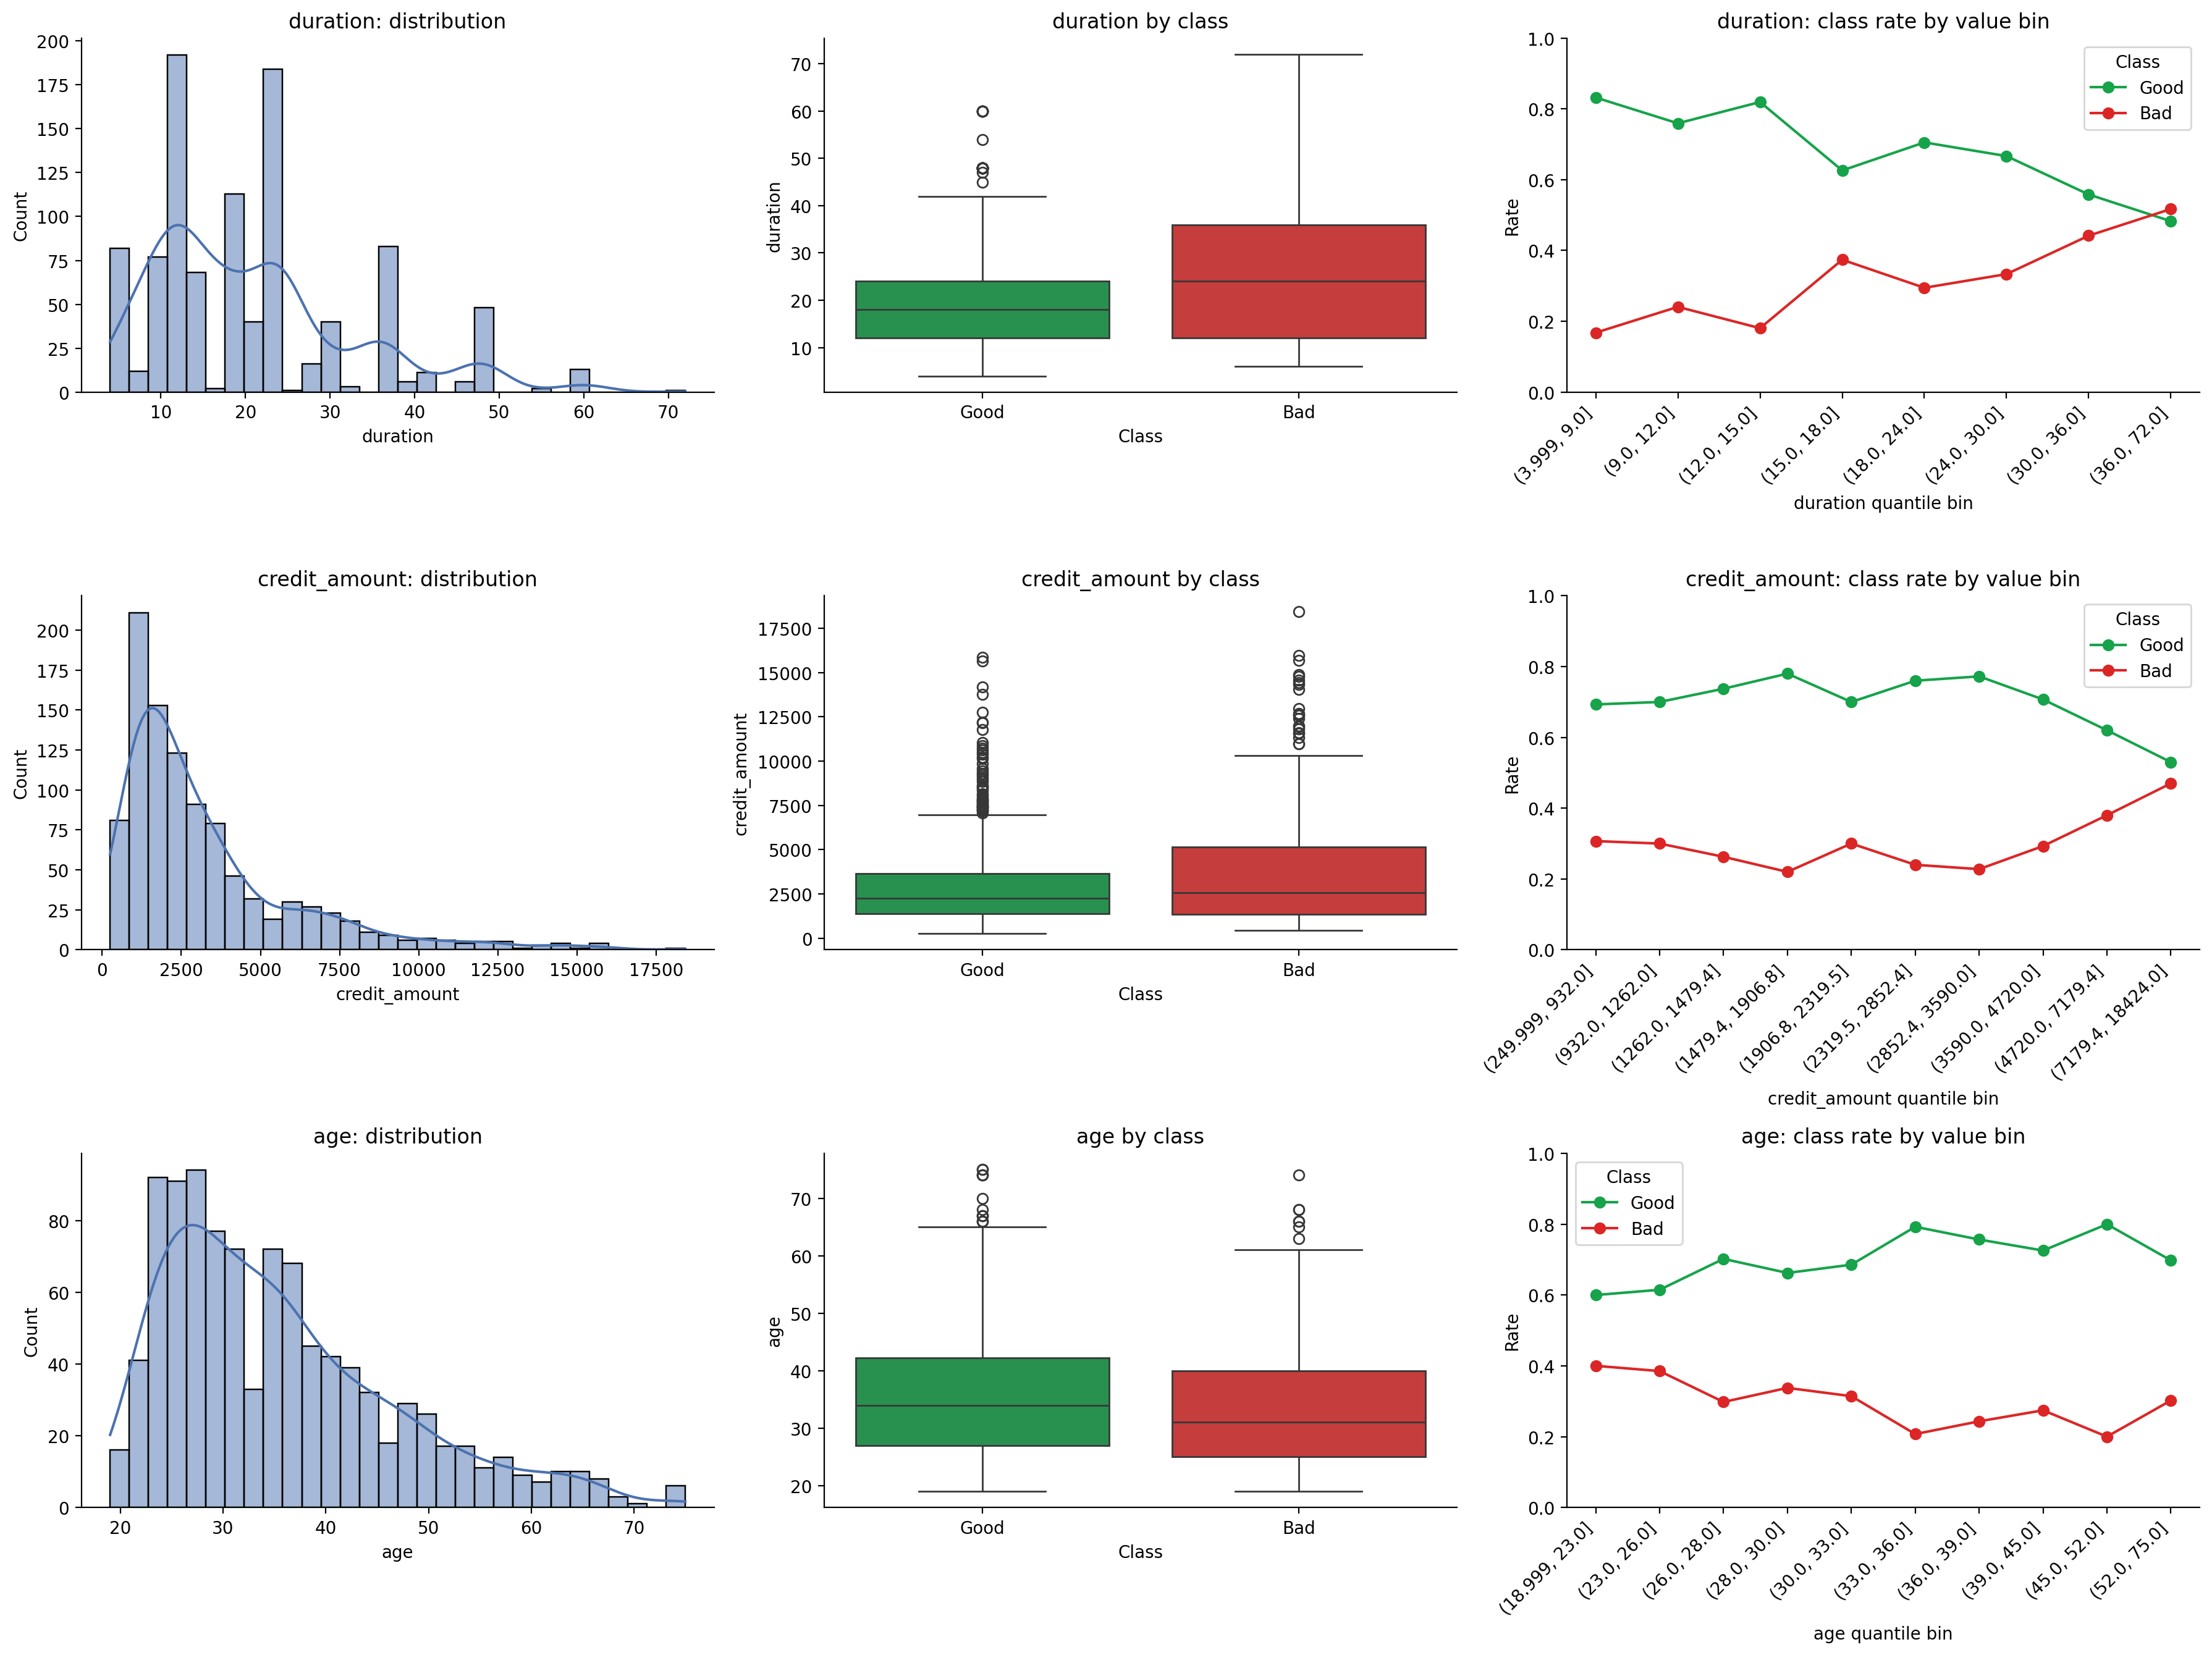

In [6]:
class_colors = {'Good': '#16a34a', 'Bad': '#dc2626'}
class_order = ['Good', 'Bad']
plot_data = dataset[numerical_columns + ['target']].copy()
plot_data['class'] = plot_data['target'].map({0: 'Good', 1: 'Bad'})

fig, axes = plt.subplots(
    nrows=len(numerical_columns),
    ncols=3,
    figsize=(18, 4.5 * len(numerical_columns)),
    squeeze=False
)

for row, col in enumerate(numerical_columns):
    ax_dist, ax_box, ax_rate = axes[row]

    # feature distribution
    if plot_data[col].nunique() <= 10:
        sns.histplot(data=plot_data, x=col, discrete=True, color='#4C72B0', ax=ax_dist)
    else:
        sns.histplot(data=plot_data, x=col, bins=30, kde=True, color='#4C72B0', ax=ax_dist)
    ax_dist.set_title(f'{col}: distribution')
    ax_dist.set_xlabel(col)
    ax_dist.set_ylabel('Count')

    # feature values by class
    sns.boxplot(
        data=plot_data, x='class', y=col, order=class_order,
        hue='class', hue_order=class_order, palette=class_colors,
        dodge=False, ax=ax_box
    )
    legend = ax_box.get_legend()
    if legend is not None:
        legend.remove()
    ax_box.set_title(f'{col} by class')
    ax_box.set_xlabel('Class')
    ax_box.set_ylabel(col)

    # good and bad rates
    feature_data = plot_data[[col, 'target']].dropna().copy()
    if feature_data[col].nunique() < 2:
        ax_rate.text(0.5, 0.5, 'Not enough distinct values', ha='center', va='center')
        ax_rate.set_axis_off()
    else:
        feature_data['feature_bin'] = pd.qcut(feature_data[col], q=10, duplicates='drop')
        rates = (
            feature_data.groupby('feature_bin', observed=True)['target']
            .agg(['count', 'mean'])
            .rename(columns={'mean': 'bad_rate'})
        )
        rates['good_rate'] = 1 - rates['bad_rate']
        x = np.arange(len(rates))
        ax_rate.plot(x, rates['good_rate'], marker='o', color=class_colors['Good'], label='Good')
        ax_rate.plot(x, rates['bad_rate'], marker='o', color=class_colors['Bad'], label='Bad')
        ax_rate.set_xticks(x, [str(interval) for interval in rates.index], rotation=45, ha='right')
        ax_rate.set_ylim(0, 1)
        ax_rate.set_title(f'{col}: class rate by value bin')
        ax_rate.set_xlabel(f'{col} quantile bin')
        ax_rate.set_ylabel('Rate')
        ax_rate.legend(title='Class')

plt.tight_layout()

- **Duration pattern:** By increasing month loans the deafualt rate increases too, although the increase is not perfectly smooth.
- **Credit amount pattern:** Credit amount is strongly right-skewed, and larger loans are associated with higher default rates, especially at the top end.
- **Age pattern:** Age dose not have clear pattern. But we can see that as the age increase the deafult rate shows a decerasing pattern. Customers under 26 have a default rate near 39%, while most age groups from 33 to 52 are around 20-27%; the oldest group is higher, so age alone does not give a simple rule.

##### 1.4.3 Outliers

In [7]:
features = ["duration", "credit_amount"]
iqr_audit_rows = []
iqr_outlier_masks = {}

for feature in features:
    values = dataset[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    mask = dataset[feature].notna() & (
        (dataset[feature] < lower_fence) | (dataset[feature] > upper_fence)
    )
    flagged = dataset.loc[mask]
    iqr_outlier_masks[feature] = mask

    value_counts = flagged[feature].value_counts().sort_index()
    if len(value_counts) > 10:
        flagged_values = (
            f"{flagged[feature].min():g}-{flagged[feature].max():g} "
            f"({len(value_counts)} distinct values)"
        )
    else:
        flagged_values = ", ".join(
            f"{value:g} (n={int(count)})" for value, count in value_counts.items()
        ) or "None"

    iqr_audit_rows.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "flagged_n": int(mask.sum()),
        "bad_rate_among_flagged": flagged["target"].mean() if len(flagged) else None,
    })

iqr_outlier_audit = pd.DataFrame(iqr_audit_rows)
display(iqr_outlier_audit.round(3))

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,bad_rate_among_flagged
0,duration,12.0,24.00,12.00,-6.000,42.000,70,0.571
1,credit_amount,1365.5,3972.25,2606.75,-2544.625,7882.375,72,0.542


Let's check whether large credit amounts align with plausible loan purposes

Out of the 72 high-amount loans, 38 are for cars and 11 are for business. This pattern supports that these amounts can reflect legitimate, larger loan requests. As it makes sense I do not remove these as outliers.

In [8]:
credit_amount_upper_fence = iqr_outlier_audit.loc[
    iqr_outlier_audit["feature"] == "credit_amount", "upper_fence"
].iloc[0]

high_amount_purposes = (
    dataset.loc[dataset["credit_amount"] > credit_amount_upper_fence]
    .groupby("purpose")
    .agg(n=("target", "size"), bad_rate=("target", "mean"))
    .sort_values("n", ascending=False)
)

display(high_amount_purposes)

,n,bad_rate
purpose,,
New car,21,0.428571
Other,17,0.588235
Retraining,11,0.727273
Furniture / equipment,7,0.142857
Business,5,0.800000
Repairs,5,0.400000
Used car,5,0.800000
Domestic appliances,1,1.000000


How often long loan terms occur?

The flagged ones are plausible loan terms in the real world. And we know that if an IQR flag identifies an unusual value, it does not prove that the record is wrong. Somebody could really got a loan with a duration of 72 months!

In [9]:
duration_upper_fence = iqr_outlier_audit.loc[
    iqr_outlier_audit["feature"] == "duration", "upper_fence"
].iloc[0]

long_duration_values = (
    dataset.loc[dataset["duration"] > duration_upper_fence]
    .groupby("duration")
    .agg(n=("target", "size"), bad_rate=("target", "mean"))
    .sort_index()
)

display(long_duration_values)

display(
    dataset.loc[
        dataset["duration"].eq(72),
        ["duration", "credit_amount", "purpose", "age"],
    ]
)

,n,bad_rate
duration,,
45,5,0.800000
47,1,0.000000
48,48,0.583333
54,2,0.500000
60,13,0.461538
72,1,1.000000


,duration,credit_amount,purpose,age
677,72,5595,Furniture / equipment,24


##### 1.4.4  Categorical distribution

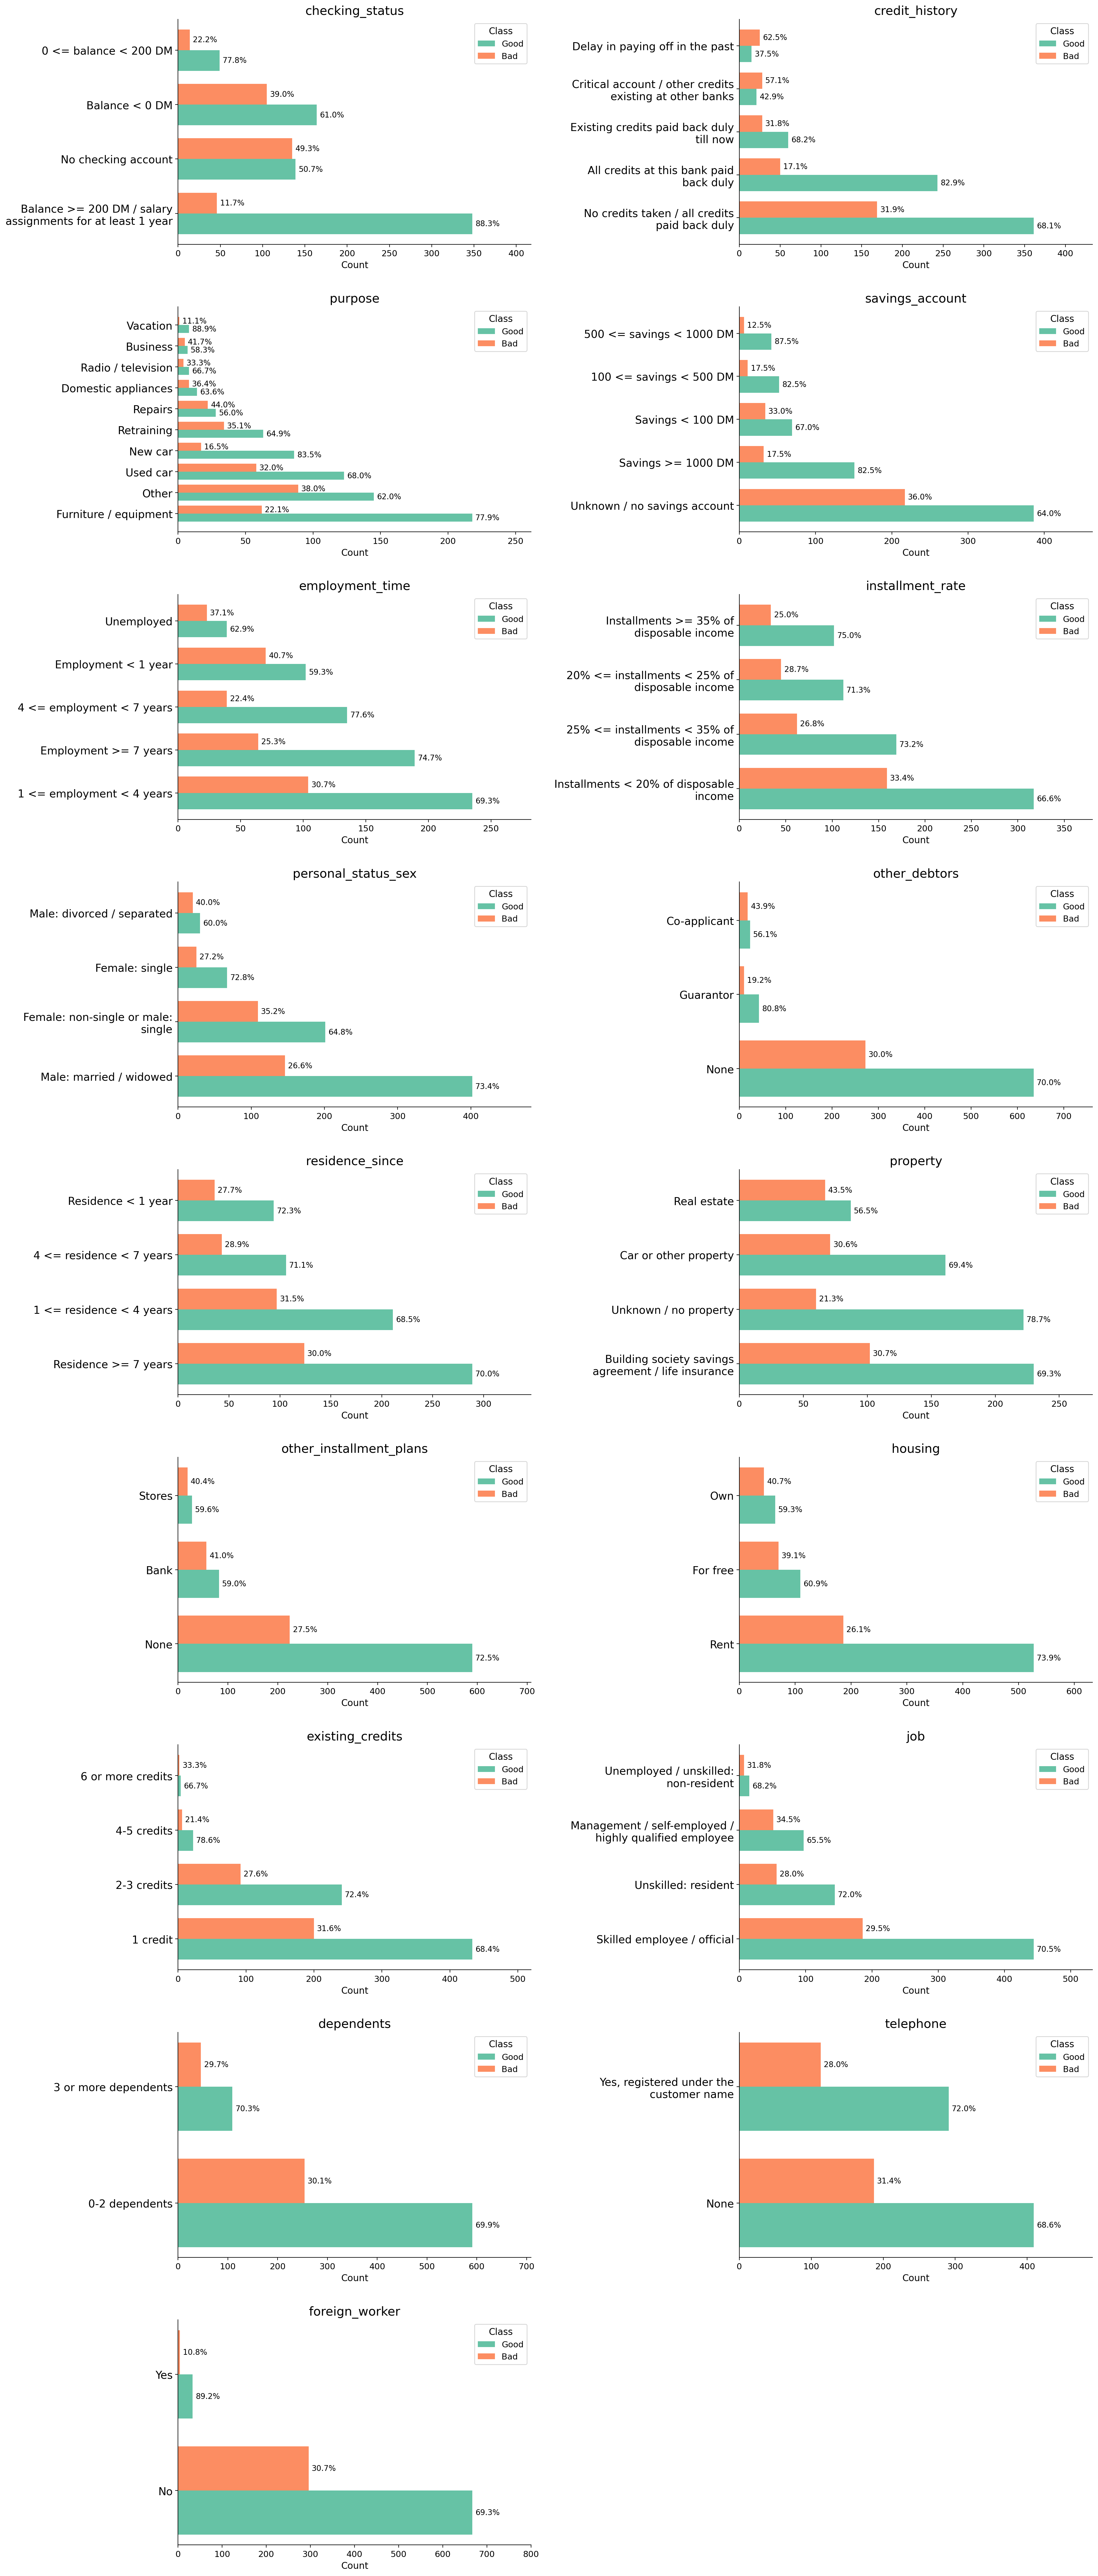

In [10]:
ncols = 2
nrows = (len(categorical_columns) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 5.2 * nrows))
axes = np.asarray(axes).ravel()
palette = sns.color_palette("Set2", n_colors=2)

for ax, col in zip(axes, categorical_columns):
    order = dataset[col].value_counts().index
    counts = (
        dataset.groupby([col, "target"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=order, columns=[0, 1], fill_value=0)
    )
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    y = np.arange(len(order))
    bar_height = 0.38

    good_bars = ax.barh(
        y - bar_height / 2, counts[0], height=bar_height,
        color=palette[0], label="Good"
    )
    bad_bars = ax.barh(
        y + bar_height / 2, counts[1], height=bar_height,
        color=palette[1], label="Bad"
    )

    for bars, target in [(good_bars, 0), (bad_bars, 1)]:
        for i, bar in enumerate(bars):
            ax.annotate(
                f"{percentages.iloc[i][target]:.1f}%",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points",
                va="center", ha="left", fontsize=10
            )

    max_count = max(counts.to_numpy().max(), 1)
    ax.set_xlim(0, max_count * 1.2)
    ax.set_title(f"{col}", fontsize=16)
    ax.set_yticks(y, labels=[
        fill(str(label), width=32, break_long_words=False, break_on_hyphens=False)
        for label in order
    ])
    ax.tick_params(axis="y", labelsize=14, rotation=0)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_xlabel("Count", fontsize=12)
    ax.set_ylabel("")
    ax.legend(title="Class", fontsize=11, title_fontsize=12)

for ax in axes[len(categorical_columns):]:
    ax.axis("off")

plt.tight_layout(h_pad=3, w_pad=3)

Comparing the bad share within each category can gives us a clearer view of risk. I will mention the interesting patterns here:

- **Checking status pattern:** The bad rate is about 11.7% for customers with a `Balance >= 200 DM` which make sense!
- **Savings pattern:** The bad rate is about 36% for people with no savings which has the highet bad rate in this feature.
- **Foreign worker pattern**: Those who are not foreign workers have a much higher bad rate (30.7%) than those who are not! (10.8%)

#### 1.5 Correlation and association

Let's find relationships between numerical and categorical features with target.

##### 1.5.1 Numerical correlations

Among numerical features, `duration` and `credit amount` have the strongest correlation with the target.it means that longer loan terms and larger amounts tend to be associated with bad outcomes.

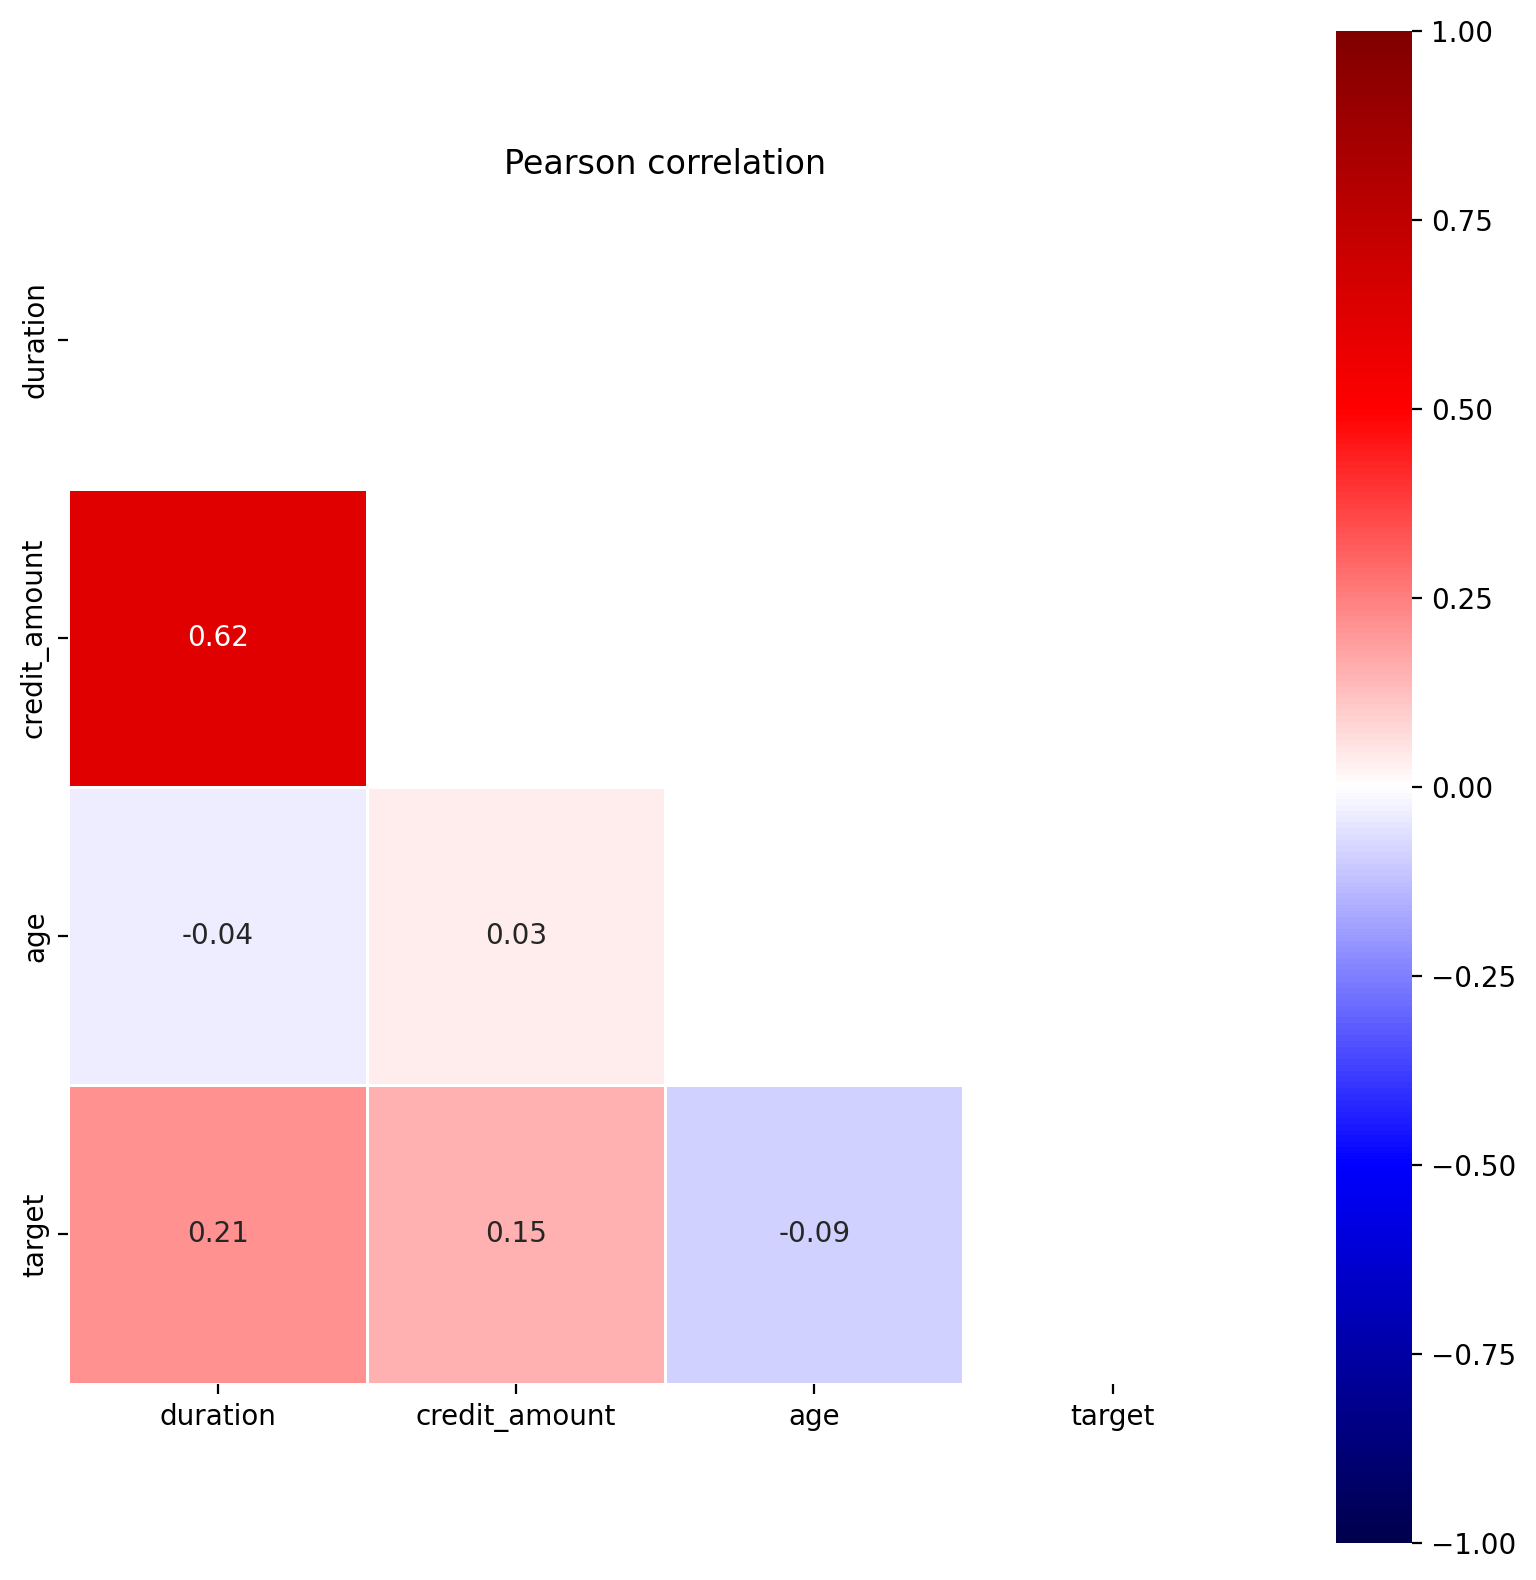

In [11]:
pearson_corr = dataset[numerical_columns + ['target']].corr(method='pearson')
upper_triangle_mask = np.triu(np.ones_like(pearson_corr, dtype=bool), k=0)

plt.figure(figsize=(8, 8))
sns.heatmap(
    pearson_corr,
    mask=upper_triangle_mask,
    annot=True,
    fmt='.2f',
    cmap='seismic',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title('Pearson correlation')
plt.tight_layout()

##### 1.5.2 Categorical associations

Category labels have no fixed numeric distance, so we do not apply `Pearson`. We need to use `Cramer's V`. As you can see, `checking_status` and `credit_history` has the highest association with target. It means the proportions of good and bad vary more across the categories of these two features than other categorical features.

In [12]:
assoc_rows = []
for assoc_feature in categorical_columns:
    assoc_counts = pd.crosstab(dataset[assoc_feature], dataset['target'])
    assoc_chi2 = chi2_contingency(assoc_counts, correction=False)[0]
    assoc_n = assoc_counts.to_numpy().sum()
    assoc_dimension = min(assoc_counts.shape[0] - 1, assoc_counts.shape[1] - 1)
    assoc_v = np.sqrt(assoc_chi2 / (assoc_n * assoc_dimension))
    assoc_rows.append({
        'Feature': assoc_feature,
        "Cramer's V": assoc_v,
    })

assoc_categorical = pd.DataFrame(assoc_rows).set_index('Feature').sort_values(
    "Cramer's V", ascending=False,
)

display(assoc_categorical.style.format({"Cramer's V": '{:.3f}'}))

,Cramer's V
Feature,
checking_status,0.352
credit_history,0.248
savings_account,0.190
purpose,0.183
property,0.154
employment_time,0.136
housing,0.135
other_installment_plans,0.113
personal_status_sex,0.098


## 2. Feature engineering and preprocessing

#### 2.1 Train/test split

In [13]:
X = dataset.drop(columns='target')
y = dataset['target']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

split_table = pd.DataFrame([
    {'subset': name, '#': len(part), '#bad': int(
        part.sum()), 'bad_rate': part.mean()}
    for name, part in [('Train', y_train), ('Test', y_test)]
])

display(split_table)

,subset,#,#bad,bad_rate
0,Train,800,240,0.3
1,Test,200,60,0.3


#### 2.2 Feature engineering 

In [14]:
def add_features(data):
    engineered = data.copy()

    # low_liquid_buffer: Checking account balance < 200 DM and savings < 100 DM.
    low_checking_balance = engineered['checking_status'].isin([
        'Balance < 0 DM',
        '0 <= balance < 200 DM'
    ])
    low_savings = engineered['savings_account'].eq('Savings < 100 DM')

    engineered['low_liquid_buffer'] = (
        low_checking_balance & low_savings
    ).astype(int)

    return engineered

X_train_engineered = X_train_raw.copy()
X_test_engineered = X_test_raw.copy()

X_train_engineered = add_features(X_train_raw)
X_test_engineered = add_features(X_test_raw)

Let's first deep dive into the new features we can create.

##### 2.2.1 `low_liquid_buffer`
$$
\begin{aligned}
\text{low\_liquid\_buffer} ={}&
\mathbf{1}\left(
\text{checking\_status} \in
\left\{
\begin{array}{l}
\text{Balance < 0 DM},\\
\text{0 <= Balance < 200 DM}
\end{array}
\right\}
\right)\\
&\times
\mathbf{1}\left(
\text{savings\_account} = \text{Savings < 100 DM}
\right)
\end{aligned}
$$

This feature indicates that an individual has both a low checking account balance and limited recorded savings. An individual with both a low checking account balance and limited savings may have less financial capacity to continue making loan installment payments when faced with unexpected expenses.

In the training set, those who have this condition have default rate of 45.7%, compared to 29% for the remaining individuals.

/tmp/ipykernel_97750/932430415.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


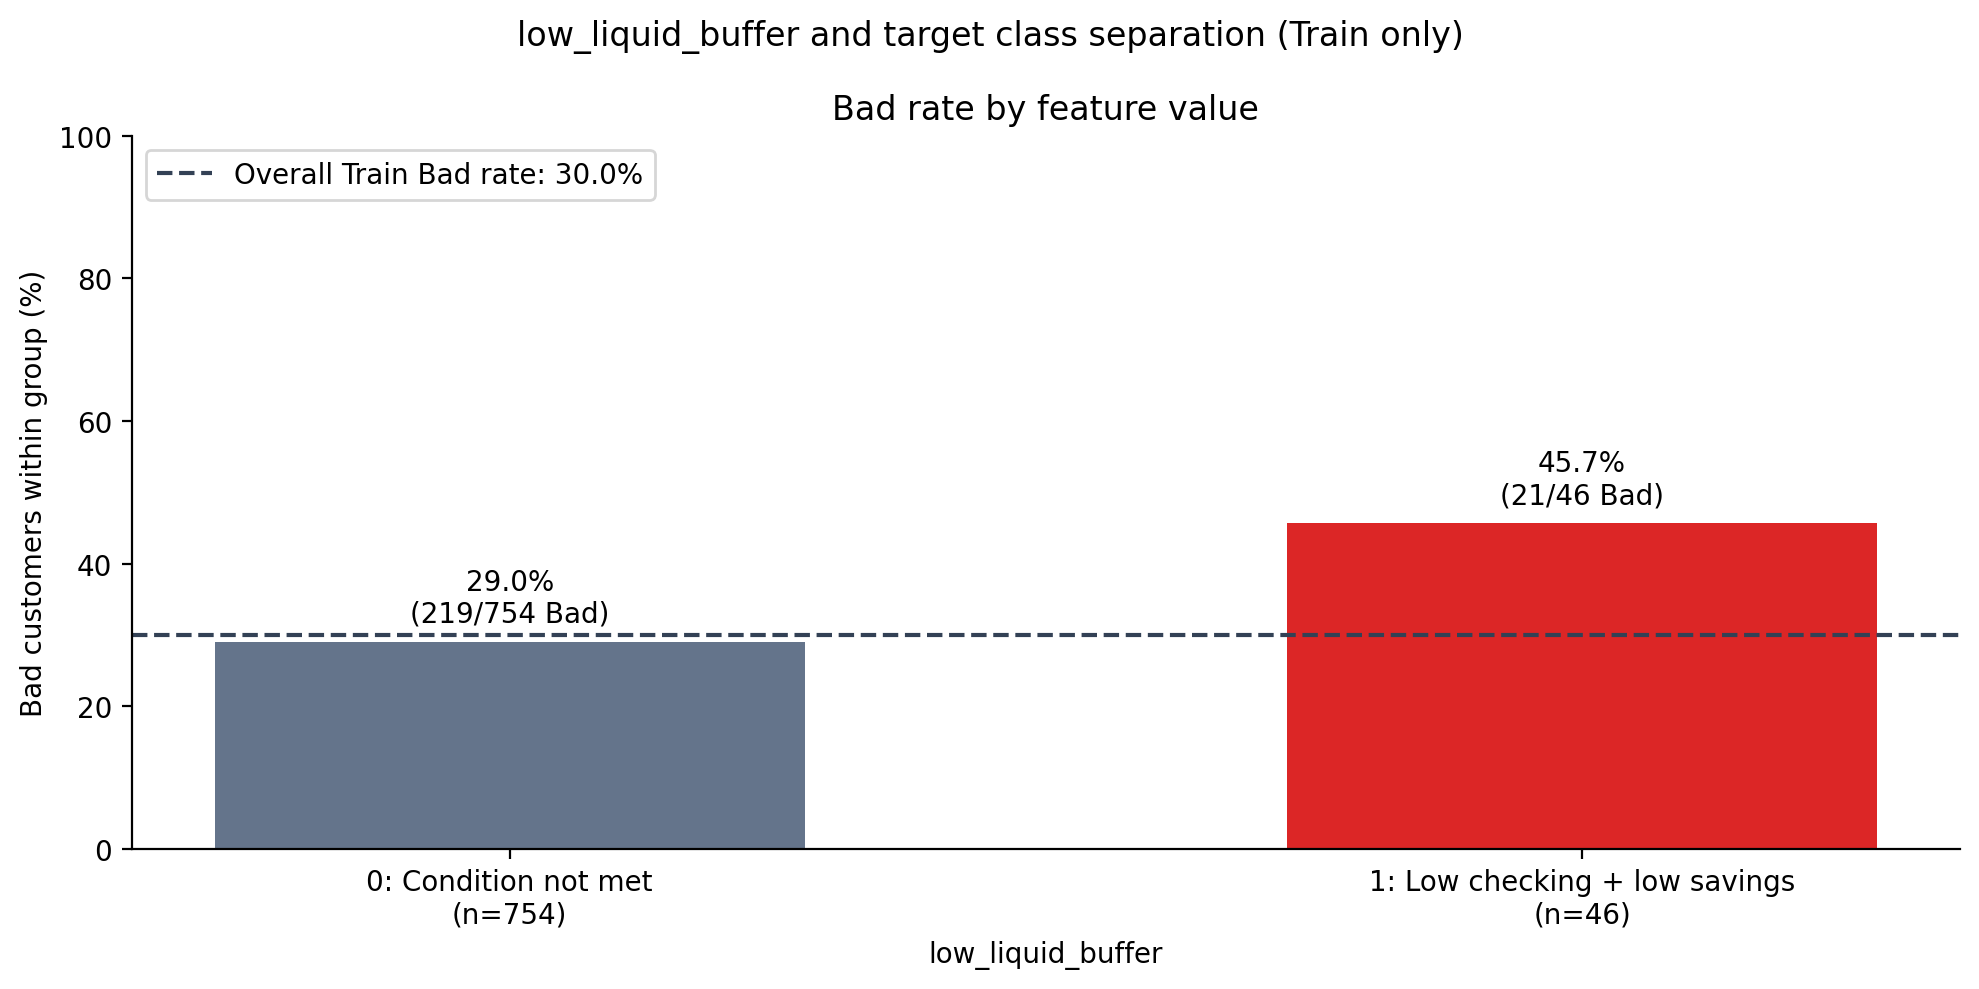

In [15]:
liquidity_plot_data = X_train_engineered[['low_liquid_buffer']].join(
    y_train.rename('target')
)
liquidity_counts = pd.crosstab(
    liquidity_plot_data['low_liquid_buffer'], liquidity_plot_data['target']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
liquidity_counts.columns = ['Good', 'Bad']
liquidity_summary = liquidity_counts.copy()
liquidity_summary['Total'] = liquidity_counts.sum(axis=1)
liquidity_summary['Bad rate (%)'] = (
    100 * liquidity_summary['Bad'] / liquidity_summary['Total']
)

group_positions = np.arange(2)
group_labels = [
    f"0: Condition not met\n(n={liquidity_summary.loc[0, 'Total']})",
    f"1: Low checking + low savings\n(n={liquidity_summary.loc[1, 'Total']})",
]

fig, ax_rate = plt.subplots(figsize=(10, 5))

bars = ax_rate.bar(
    group_positions, liquidity_summary['Bad rate (%)'],
    width=0.55, color=['#64748b', '#dc2626']
)
ax_rate.bar_label(
    bars,
    labels=[
        f"{row['Bad rate (%)']:.1f}%\n({int(row['Bad'])}/{int(row['Total'])} Bad)"
        for _, row in liquidity_summary.iterrows()
    ],
    padding=5,
)
ax_rate.axhline(
    y_train.mean() * 100, color='#334155', linestyle='--',
    label=f'Overall Train Bad rate: {y_train.mean():.1%}'
)
ax_rate.set_xticks(group_positions, group_labels)
ax_rate.set_xlabel('low_liquid_buffer')
ax_rate.set_ylabel('Bad customers within group (%)')
ax_rate.set_title('Bad rate by feature value')
ax_rate.set_ylim(0, 100)
ax_rate.legend(loc='upper left')

fig.suptitle('low_liquid_buffer and target class separation (Train only)')
fig.tight_layout()
fig.show()

##### 2.2.3 Top-3 key features
Let's calculate `Weight of Evidence (WoE)` and `Information Value (IV)` for each feature to identify which features have the greatest discriminatory power.

- WOE: A positive WOE indicates a higher proportion of good customers, while a negative WOE indicates a higher proportion of bad customers.
- IV: The higher the IV, the greater the feature's discriminatory power.

`Checking account status` has the highest IV (0.60). `Credit history` is a good feature too (0.26). It shows that past repayment behavior are especially useful for separating good and bad borrowers

In [16]:
iv_data = X_train_engineered.copy()
iv_data['target'] = y_train
iv_rows = []
woe_tables = {}

for feature in X_train_engineered.columns:
    feature_group = iv_data[feature]
    if feature in numerical_columns and feature_group.nunique() > 5:
        feature_group = pd.qcut(feature_group, q=5, duplicates='drop')

    woe_table = iv_data.groupby(
        feature_group, observed=False
    )['target'].agg(Total='size', Bad='sum')
    woe_table['Good'] = woe_table['Total'] - woe_table['Bad']

    woe_table['Bad_Dist'] = (woe_table['Bad'] + 0.5) / (
        woe_table['Bad'].sum() + 0.5 * len(woe_table)
    )
    woe_table['Good_Dist'] = (woe_table['Good'] + 0.5) / (
        woe_table['Good'].sum() + 0.5 * len(woe_table)
    )
    woe_table['WOE'] = np.log(
        woe_table['Good_Dist'] / woe_table['Bad_Dist']
    )
    woe_table['IV'] = (
        woe_table['Good_Dist'] - woe_table['Bad_Dist']
    ) * woe_table['WOE']

    iv_rows.append({'Feature': feature, 'IV': woe_table['IV'].sum()})
    woe_tables[feature] = woe_table

iv_summary = pd.DataFrame(iv_rows).set_index('Feature').sort_values(
    'IV', ascending=False
)

top_5_features = iv_summary.head(5)
print('Top-5 key features:')
display(top_5_features)

for feature in top_5_features.index:
    display(woe_tables[feature])

Top-5 key features:


,IV
Feature,
checking_status,0.609259
credit_history,0.262438
savings_account,0.214128
duration,0.213244
purpose,0.149895


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
checking_status,,,,,,,
0 <= balance < 200 DM,51,13,38,0.055785,0.068505,0.205404,0.002613
Balance < 0 DM,214,84,130,0.349174,0.232206,-0.407942,0.047716
Balance >= 200 DM / salary assignments for at least 1 year,316,38,278,0.159091,0.495552,1.136196,0.382285
No checking account,219,105,114,0.435950,0.203737,-0.760700,0.176645


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
credit_history,,,,,,,
All credits at this bank paid back duly,240,42,198,0.175258,0.352889,0.699896,0.124323
Critical account / other credits existing at other banks,41,22,19,0.092784,0.034667,-0.984490,0.057215
Delay in paying off in the past,31,19,12,0.080412,0.022222,-1.286075,0.074837
Existing credits paid back duly till now,72,23,49,0.096907,0.088000,-0.096417,0.000859
No credits taken / all credits paid back duly,416,134,282,0.554639,0.502222,-0.099275,0.005204


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
savings_account,,,,,,,
100 <= savings < 500 DM,50,8,42,0.035052,0.075556,0.768048,0.031109
500 <= savings < 1000 DM,41,5,36,0.022680,0.064889,1.051175,0.044368
Savings < 100 DM,90,30,60,0.125773,0.107556,-0.156473,0.002851
Savings >= 1000 DM,144,24,120,0.101031,0.214222,0.751587,0.085073
Unknown / no savings account,475,173,302,0.715464,0.537778,-0.285486,0.050727


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
duration,,,,,,,
"(3.999, 12.0]",288,59,229,0.245361,0.408000,0.508537,0.082708
"(12.0, 15.0]",60,11,49,0.047423,0.088000,0.618236,0.025086
"(15.0, 24.0]",270,92,178,0.381443,0.317333,-0.184009,0.011797
"(24.0, 30.0]",44,14,30,0.059794,0.054222,-0.097811,0.000545
"(30.0, 60.0]",138,64,74,0.265979,0.132444,-0.697256,0.093108


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
purpose,,,,,,,
Business,6,2,4,0.010204,0.007965,-0.247781,0.000555
Domestic appliances,18,7,11,0.030612,0.020354,-0.408124,0.004187
Furniture / equipment,215,46,169,0.189796,0.300000,0.457833,0.050455
New car,84,16,68,0.067347,0.121239,0.587906,0.031683
Other,194,70,124,0.287755,0.220354,-0.266875,0.017988
Radio / television,10,3,7,0.014286,0.013274,-0.073427,0.000074
Repairs,40,20,20,0.083673,0.036283,-0.835568,0.039598
Retraining,79,26,53,0.108163,0.094690,-0.133031,0.001792
Used car,149,49,100,0.202041,0.177876,-0.127382,0.003078


#### 2.3 Encoding and scaling

We use ‍`One-Hot Encoding` for categorical features so the model does not treat one label as larger than another.

In [17]:
X_train_encoded = pd.get_dummies(
    X_train_engineered, columns=categorical_columns, dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_engineered, columns=categorical_columns, dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

We should not use scalling for all model types. For example, `Logistic Regression` is sensitive to the scale of input features, so it is recommended to do the scalling. On the other hand, `Tree-based models` rely on the ordering of feature values rather than their numerical scale.

In [18]:
scaler = StandardScaler()
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Train: learn parameters and transform
X_train_scaled[numerical_columns] = scaler.fit_transform(X_train_encoded[numerical_columns])

# Test: transform only
X_test_scaled[numerical_columns] = scaler.transform(X_test_encoded[numerical_columns])

## 3. Modeling

#### 3.1 Baseline model

I trained a `Decision Tree` model on the training observations using the unscaled,
one-hot encoded features from section 2.3.

Based on the provided guide for this final project, I fix `max_depth=4` and `min_samples_leaf=30` before evaluation to limit tree complexity, and there is no hyperparameter or threshold tuning in this baseline.

In [19]:
baseline_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=SEED,
)
baseline_model.fit(X_train_encoded, y_train)

baseline_train_predictions = baseline_model.predict(X_train_encoded)
baseline_train_probabilities = baseline_model.predict_proba(X_train_encoded)[:, 1]
baseline_test_predictions = baseline_model.predict(X_test_encoded)
baseline_test_probabilities = baseline_model.predict_proba(X_test_encoded)[:, 1]

baseline_train_precision, baseline_train_recall, _ = precision_recall_curve(
    y_train, baseline_train_probabilities
)
baseline_test_precision, baseline_test_recall, _ = precision_recall_curve(
    y_test, baseline_test_probabilities
)
baseline_results = pd.DataFrame({
    'ROC-AUC': [
        roc_auc_score(y_train, baseline_train_probabilities),
        roc_auc_score(y_test, baseline_test_probabilities),
    ],
    'PR-AUC': [
        auc(baseline_train_recall, baseline_train_precision),
        auc(baseline_test_recall, baseline_test_precision),
    ],
    'Precision': [
        precision_score(y_train, baseline_train_predictions),
        precision_score(y_test, baseline_test_predictions),
    ],
    'Recall': [
        recall_score(y_train, baseline_train_predictions),
        recall_score(y_test, baseline_test_predictions),
    ],
    'Brier score': [
        brier_score_loss(y_train, baseline_train_probabilities),
        brier_score_loss(y_test, baseline_test_probabilities),
    ],
}, index=['Train', 'Test'])

display(baseline_results.round(4))

,ROC-AUC,PR-AUC,Precision,Recall,Brier score
Train,0.8022,0.6283,0.6250,0.6042,0.1557
Test,0.6843,0.3889,0.4603,0.4833,0.2060


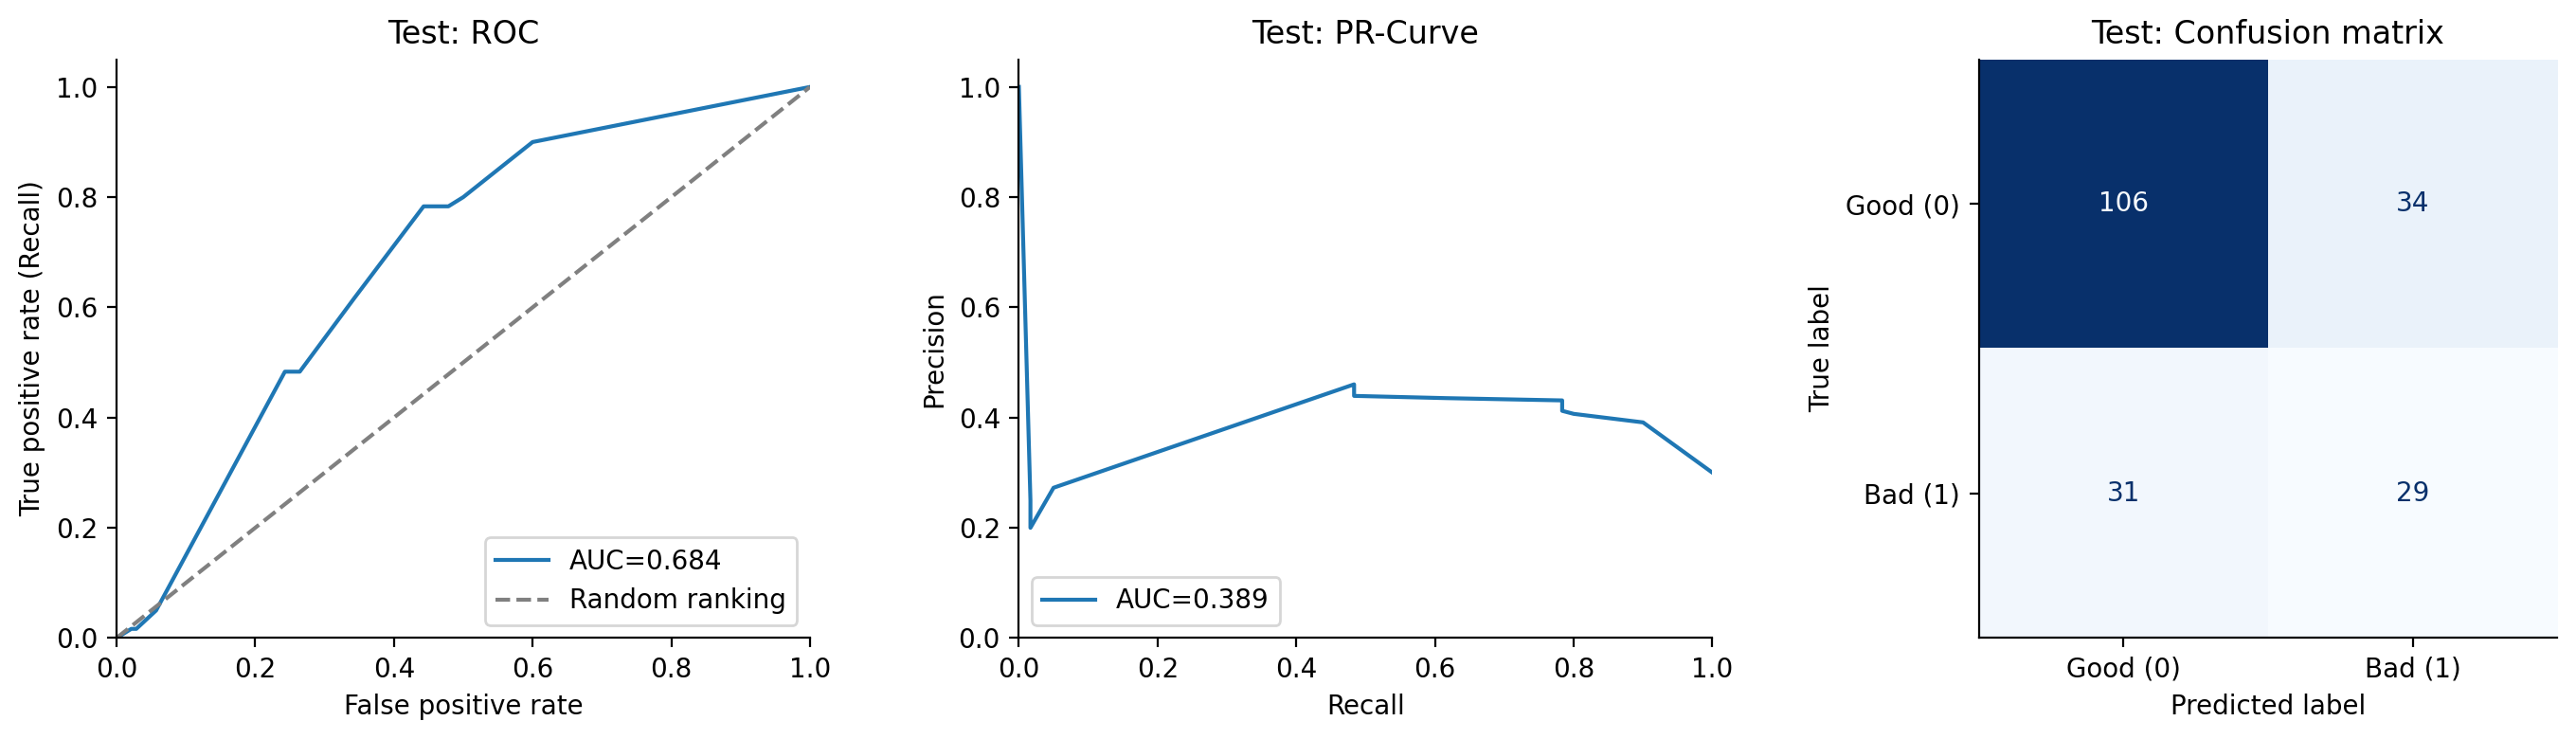

In [20]:
baseline_fig, baseline_axes = plt.subplots(1, 3, figsize=(14, 4))

baseline_fpr, baseline_tpr, _ = roc_curve(y_test, baseline_test_probabilities)
baseline_axes[0].plot(
    baseline_fpr, baseline_tpr,
    label=f"AUC={baseline_results.loc['Test', 'ROC-AUC']:.3f}",
)

baseline_axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
baseline_axes[0].set(
    title='Test: ROC', xlabel='False positive rate',
    ylabel='True positive rate (Recall)', xlim=(0, 1), ylim=(0, 1.05),
)
baseline_axes[0].legend(loc='lower right')

baseline_axes[1].plot(
    baseline_test_recall, baseline_test_precision,
    label=f"AUC={baseline_results.loc['Test', 'PR-AUC']:.3f}",
)

baseline_axes[1].set(
    title='Test: PR-Curve', xlabel='Recall', ylabel='Precision',
    xlim=(0, 1), ylim=(0, 1.05),
)
baseline_axes[1].legend(loc='lower left')

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_test_predictions,
    labels=[0, 1], display_labels=['Good (0)', 'Bad (1)'],
    cmap='Blues', colorbar=False, values_format='d', ax=baseline_axes[2],
)
baseline_axes[2].set_title('Test: Confusion matrix')
baseline_fig.tight_layout()

#### 3.2 Hyperparameter tuning

Let's use more advanced models and find the best hyperparameters for them using cross validation.

In [32]:
def pr_auc_score(y_true, y_probability):
    precision, recall, _ = precision_recall_curve(y_true, y_probability)
    return auc(recall, precision)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

model_specs = {
    'Decision Tree': (
        DecisionTreeClassifier(random_state=SEED),
        {
            'model__max_depth': [2, 4, 8],
            'model__min_samples_leaf': [10, 15, 30],
            'model__class_weight': [None, 'balanced'],
            'model__criterion': ['gini', 'entropy'],
        },
    ),
    'Random Forest': (
        RandomForestClassifier(n_jobs=1, random_state=SEED),
        {
            'model__n_estimators': [50, 100, 150, 200],
            'model__max_depth': [2, 4, 8],
            'model__min_samples_leaf': [10, 15, 30],
            'model__class_weight': [None, 'balanced'],
            'model__criterion': ['gini', 'entropy'],
        },
    ),
    'Logistic Regression': (
        LogisticRegression(max_iter=5000, random_state=SEED),
        [
            {
                'model__C': [0.1, 1, 10],
                'model__class_weight': [None, 'balanced'],
                'model__penalty': ['l1', 'l2'],
                'model__solver': ['liblinear'],
            },
            {
                'model__C': [0.1, 1, 10],
                'model__class_weight': [None, 'balanced'],
                'model__penalty': ['elasticnet'],
                'model__solver': ['saga'],
                'model__l1_ratio': [0.25, 0.5, 0.75],
            },
        ],
    ),
    'XGBoost': (
        XGBClassifier(
            eval_metric='logloss', n_jobs=1, random_state=SEED,
            subsample=1, colsample_bytree=1,
        ),
        {
            'model__n_estimators': [50, 100, 150, 200],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__max_depth': [2, 4, 8],
        },
    )
}

searches, models, cv_rows = {}, {}, []
for name, (estimator, grid) in model_specs.items():
    # LR scales inside each CV fold.
    if name == 'Logistic Regression':
        pipeline = Pipeline([('scaler', StandardScaler()), ('model', estimator)])
    elif name == 'XGBoost':
        # one-hot column names contain '<'; XGBoost needs an array for these names.
        pipeline = Pipeline([
            ('to_array', FunctionTransformer(np.asarray, validate=True)),
            ('model', estimator),
        ])
    else:
        pipeline = Pipeline([('model', estimator)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, n_jobs=-1, refit='ROC_AUC',
        scoring={
            'ROC_AUC': 'roc_auc',
            'PR_AUC': make_scorer(pr_auc_score, response_method='predict_proba'),
            'Precision': make_scorer(precision_score, zero_division=0),
            'Recall': make_scorer(recall_score, zero_division=0),
            'Brier': 'neg_brier_score',
        },
        return_train_score=True, error_score='raise', verbose=1,
    )
    search.fit(X_train_encoded, y_train)
    searches[name] = search
    models[name] = search.best_estimator_

    i = search.best_index_
    cv_rows.append({
        'model': name,
        'ROC_AUC': search.best_score_,
        'AUC_std': search.cv_results_['std_test_ROC_AUC'][i],
        'Train_AUC': search.cv_results_['mean_train_ROC_AUC'][i],
        'PR_AUC': search.cv_results_['mean_test_PR_AUC'][i],
        'Precision': search.cv_results_['mean_test_Precision'][i],
        'Recall': search.cv_results_['mean_test_Recall'][i],
        'Brier': -search.cv_results_['mean_test_Brier'][i],
    })
    print(name, search.best_params_)

cv_table = pd.DataFrame(cv_rows).set_index('model').sort_values(
    'Brier', ascending=True
)

display(cv_table)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


Decision Tree {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 30}
Fitting 5 folds for each of 144 candidates, totalling 720 fits
Random Forest {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 10, 'model__n_estimators': 150}
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Logistic Regression {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Fitting 5 folds for each of 36 candidates, totalling 180 fits
XGBoost {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 150}


,ROC_AUC,AUC_std,Train_AUC,PR_AUC,Precision,Recall,Brier
model,,,,,,,
XGBoost,0.787314,0.044455,0.924594,0.583710,0.623465,0.429167,0.167354
Random Forest,0.788802,0.046957,0.902530,0.602470,0.698636,0.125000,0.172922
Decision Tree,0.729092,0.056303,0.820672,0.541112,0.585321,0.425000,0.185321
Logistic Regression,0.768304,0.054435,0.831257,0.569894,0.496530,0.737500,0.199598


#### 3.3 Model selection

The dataset documentation (`german.doc`) introduces the following cost matrix:

| Actual / Predicted | Good (0) | Bad (1) |
|--------------------|----------|---------|
| Good (0)           | 0        | 1       |
| Bad (1)            | 5        | 0       |

Misclassifying a bad customer as good has a cost of 5, whereas misclassifying a good customer as bad has a cost of 1.

- So, from a business perspective, minimizing our cost means maximizing our gain!

- To find the optimal cut-off for each model, I used the following formula: **`Cost = 5 × (FN + FP)`**. 

- We select the cut-off that minimizes this cost. We then reject an application if `P(Bad) >= cut-off`, otherwise, we approve it.

In [35]:
neg_label, pos_label = 0, 1  # good, bad

def credit_gain_score(y_true, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y_true, y_pred, labels=[neg_label, pos_label])
    gain_matrix = np.array([[0, -1], [-5, 0]])
    return np.sum(cm * gain_matrix)

credit_gain_scorer = make_scorer(
    credit_gain_score, neg_label=neg_label, pos_label=pos_label
)

cv_winner = cv_table.sort_values('Brier', ascending=True).index[0]

def ranking_metrics(actual, probabilities):
    precision, recall, _ = precision_recall_curve(actual, probabilities)
    fpr, tpr, _ = roc_curve(actual, probabilities)
    roc_auc = roc_auc_score(actual, probabilities)
    return {'ROC_AUC': roc_auc, 'PR_AUC': auc(recall, precision),
            'AP': average_precision_score(actual, probabilities), 'Gini': 2 * roc_auc - 1,
            'KS': np.max(np.abs(tpr - fpr)), 'Brier': brier_score_loss(actual, probabilities)}


def decision_metrics(actual, probabilities, threshold):
    predicted = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    approved = tn + fn
    cost = 5 * fn + fp
    return {'threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Cost': cost, 'Cost_per_applicant': cost / len(actual),
            'Approval': approved / len(actual), 'Approved_bad_rate': fn / approved if approved else np.nan,
            'Recall': recall_score(actual, predicted, zero_division=0),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'FPR': fp / (fp + tn) if fp + tn else np.nan,
            'FNR': fn / (fn + tp) if fn + tp else np.nan,
            'F1': f1_score(actual, predicted, zero_division=0),
            'Accuracy': accuracy_score(actual, predicted)}


tuned_models, thresholds, cv_threshold_rows = {}, {}, []
for name, model in models.items():
    tuned_model = TunedThresholdClassifierCV(
        estimator=clone(model),
        scoring=credit_gain_scorer,
        response_method='predict_proba',
        thresholds=100,
        cv=5,
        refit=True,
        store_cv_results=True,
    )
    tuned_model.fit(X_train_encoded, y_train)
    tuned_models[name] = tuned_model
    thresholds[name] = float(tuned_model.best_threshold_)
    default_gain = cross_val_score(
        clone(model), X_train_encoded, y_train,
        scoring=credit_gain_scorer, cv=5, n_jobs=1,
    ).mean()
    cv_threshold_rows.append({
        'model': name,
        'threshold': thresholds[name],
        'CV_credit_gain': tuned_model.best_score_,
        'CV_mean_cost': -tuned_model.best_score_,
        'CV_mean_cost_at_0.5': -default_gain,
    })

final_name = cv_winner
final_tuned_model = tuned_models[final_name]
final_model = final_tuned_model.estimator_
final_threshold = thresholds[final_name]

threshold_test_probabilities, threshold_rows = {}, []
for name in tuned_models:
    p = tuned_models[name].predict_proba(X_test_encoded)[:, 1]
    threshold_test_probabilities[name] = p
    at_default = decision_metrics(y_test, p, 0.5)
    selected = decision_metrics(y_test, p, thresholds[name])
    threshold_rows.append({
        'model': name,
        **ranking_metrics(y_test, p), **selected,
        'Cost_at_0.5': at_default['Cost'],
    })

threshold_comparison = pd.DataFrame(threshold_rows).set_index('model')
comparison_columns = [
    'threshold', 'ROC_AUC', 'PR_AUC', 'Brier',
    'Accuracy', 'Recall', 'Precision', 'FP', 'FN', 'Cost',
    'Cost_at_0.5', 'Approval', 'Approved_bad_rate',
]

print('Test comparison: cut-offs using Train CV')
display(threshold_comparison[comparison_columns].round(4))
winner_result = threshold_comparison.loc[final_name]
print(f'Final model: {final_name} | cut-off: {final_threshold:.6f}')
print(f'Decision: reject if P(Bad) >= {final_threshold:.6f}; otherwise approve.')

Test comparison: cut-offs using Train CV


,threshold,ROC_AUC,PR_AUC,Brier,Accuracy,Recall,Precision,FP,FN,Cost,Cost_at_0.5,Approval,Approved_bad_rate
model,,,,,,,,,,,,,
Decision Tree,0.0968,0.6829,0.4862,0.2012,0.505,0.8833,0.3655,92,7,127,213,0.275,0.1273
Random Forest,0.2272,0.7883,0.6127,0.1707,0.555,0.9167,0.3957,84,5,109,225,0.305,0.0820
Logistic Regression,0.3657,0.8040,0.6283,0.1894,0.595,0.8833,0.4173,74,7,109,103,0.365,0.0959
XGBoost,0.1144,0.8004,0.6133,0.1588,0.535,0.9500,0.3878,90,3,105,160,0.265,0.0566


Final model: XGBoost | cut-off: 0.114408
Decision: reject if P(Bad) >= 0.114408; otherwise approve.


**Note:** As a bussiness, if we want a higher approval rate we need to change the cost matrix. For example, if we change the current cost matrix to `[[0, -1], [-3, 0]]` the approval rate goes up to around 50%.

Let's plot the results!

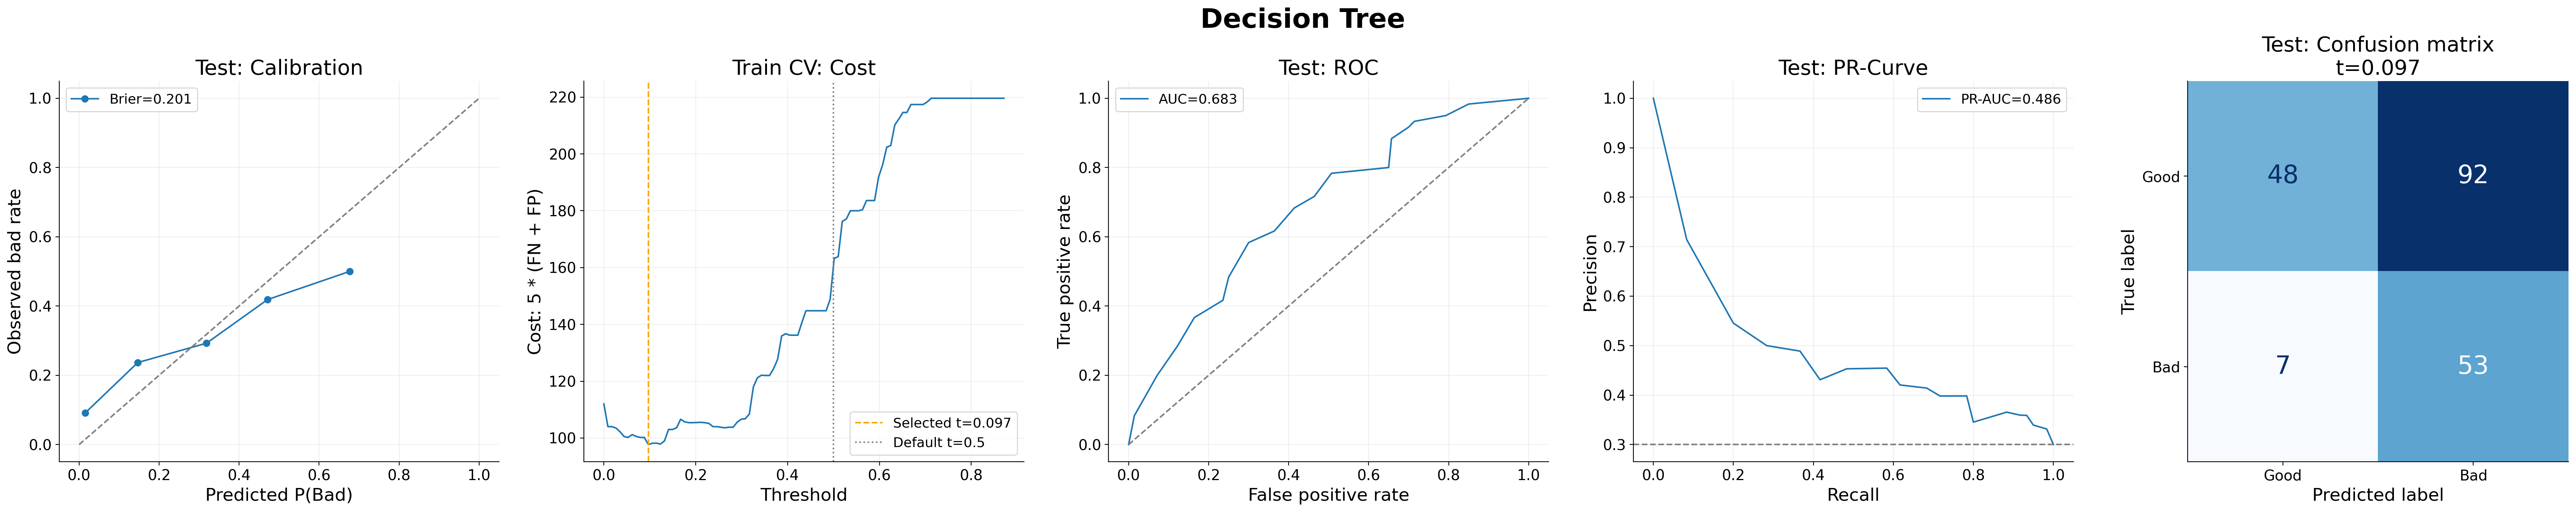

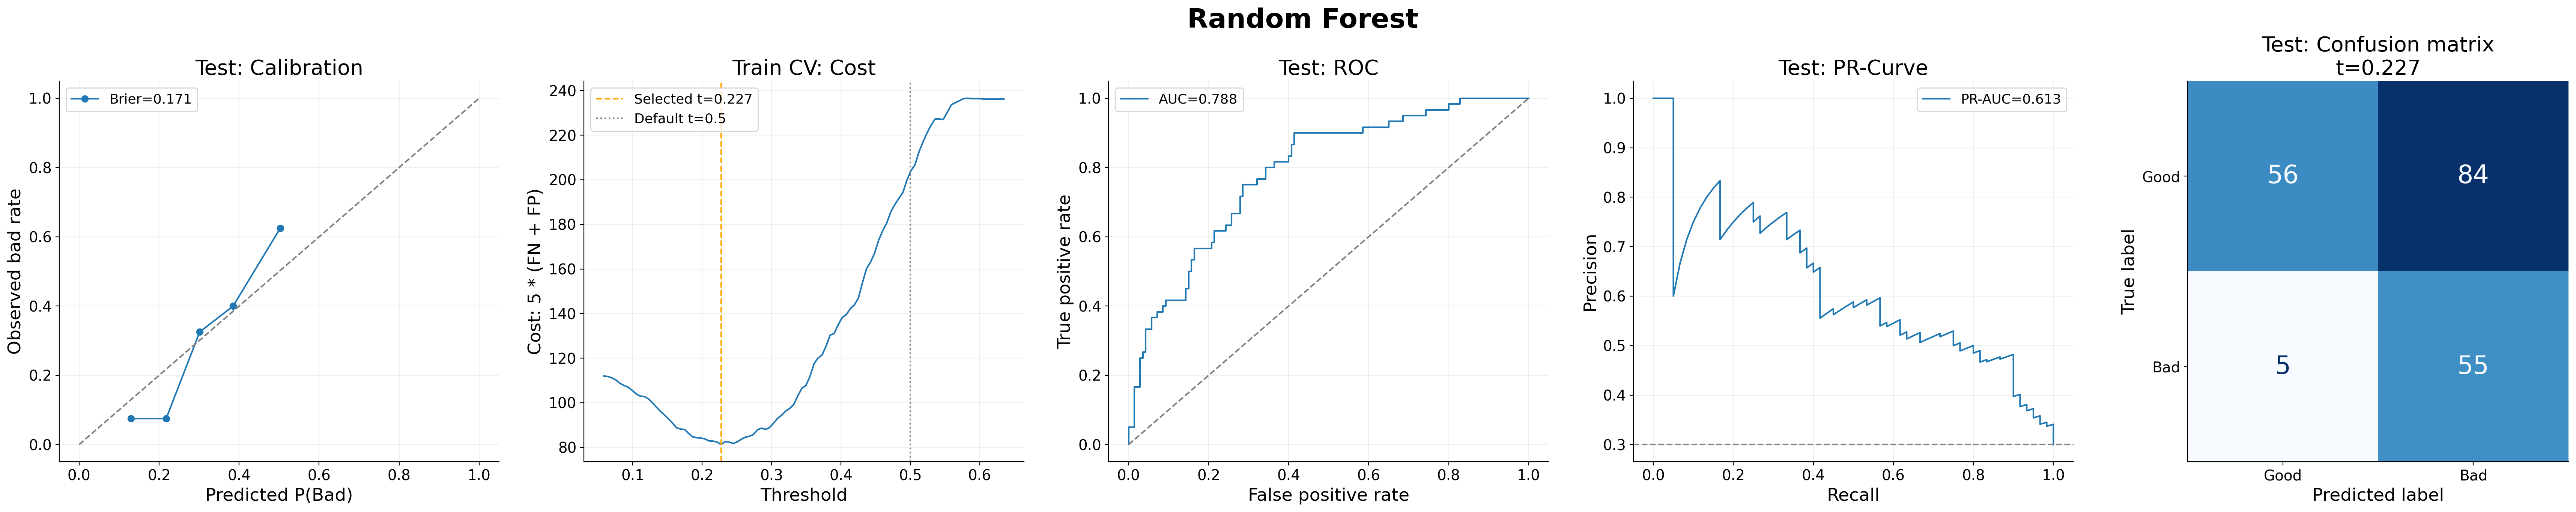

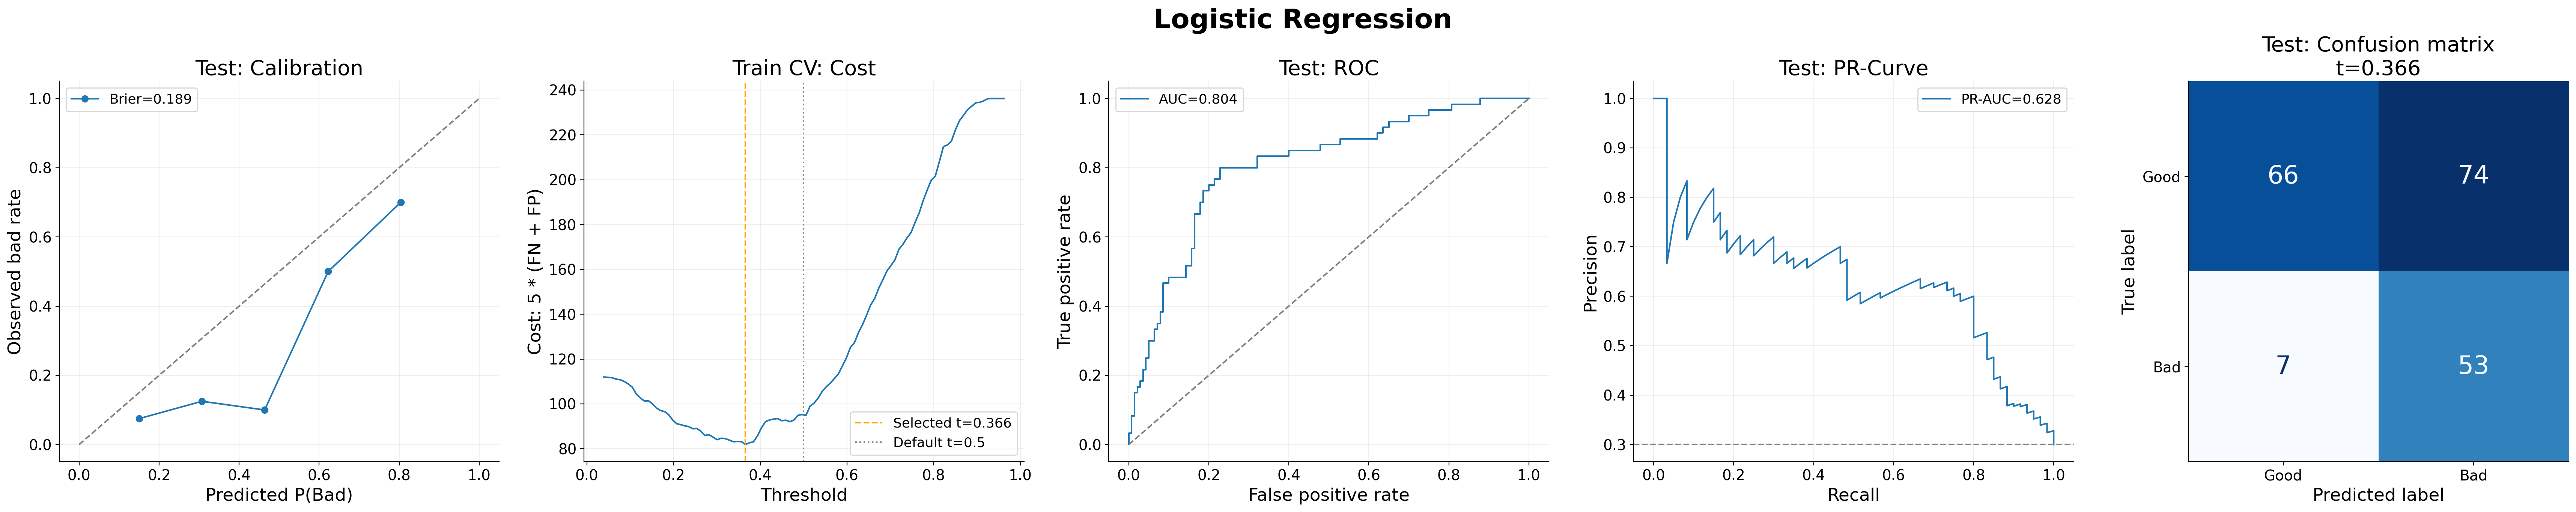

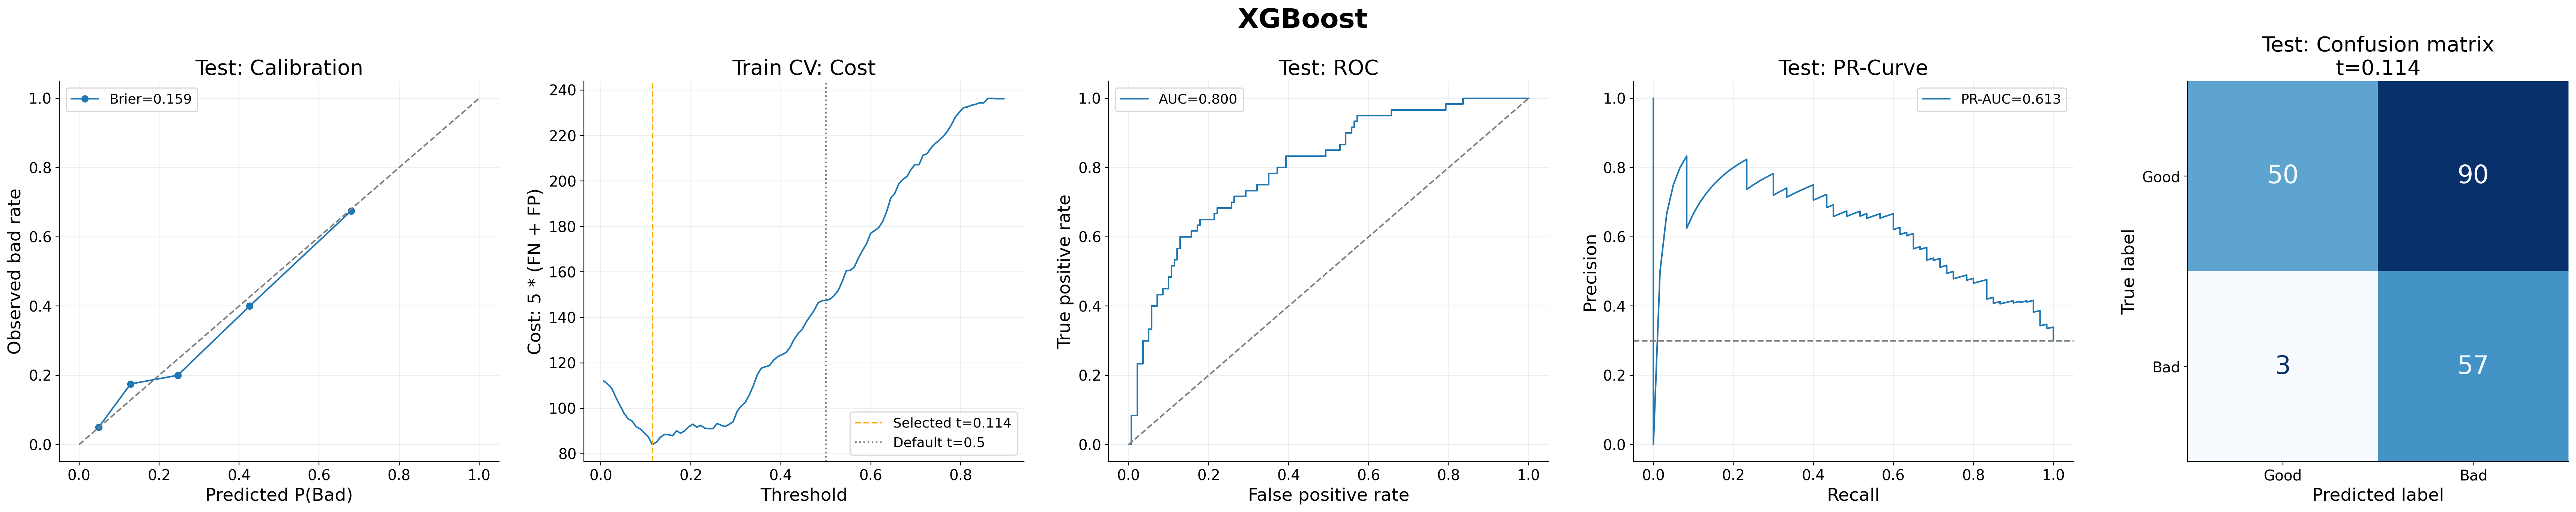

In [23]:
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
})

for name, model in tuned_models.items():
    p = threshold_test_probabilities[name]
    t = thresholds[name]

    fig, ax = plt.subplots(1, 5, figsize=(35, 7))

    # Calibration
    observed, predicted = calibration_curve(
        y_test, p, n_bins=5, strategy="quantile"
    )
    ax[0].plot(predicted, observed, "o-",
               label=f"Brier={brier_score_loss(y_test, p):.3f}")
    ax[0].plot([0, 1], [0, 1], "--", color="gray")
    ax[0].set(title="Test: Calibration",
              xlabel="Predicted P(Bad)", ylabel="Observed bad rate")

    # Cost versus threshold: Train CV
    ax[1].plot(model.cv_results_["thresholds"],
               -np.asarray(model.cv_results_["scores"]))
    ax[1].axvline(t, color="orange", linestyle="--",
                 label=f"Selected t={t:.3f}")
    ax[1].axvline(0.5, color="gray", linestyle=":", label="Default t=0.5")
    ax[1].set(title="Train CV: Cost",
              xlabel="Threshold", ylabel="Cost: 5 * (FN + FP)")

    # ROC
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[2].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, p):.3f}")
    ax[2].plot([0, 1], [0, 1], "--", color="gray")
    ax[2].set(title="Test: ROC",
              xlabel="False positive rate", ylabel="True positive rate")

    # Precision-Recall
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax[3].plot(recall, precision,
               label=f"PR-AUC={auc(recall, precision):.3f}")
    ax[3].axhline(np.mean(y_test), color="gray", linestyle="--")
    ax[3].set(title="Test: PR-Curve",
              xlabel="Recall", ylabel="Precision")

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= t).astype(int),
        labels=[0, 1], display_labels=["Good", "Bad"],
        cmap="Blues", colorbar=False, ax=ax[4],
        text_kw={"fontsize": 24},
    )
    ax[4].set_title(f"Test: Confusion matrix\nt={t:.3f}")

    for a in ax[:4]:
        a.legend()
        a.grid(alpha=0.2)

    fig.suptitle(name, fontsize=26, fontweight="bold")
    plt.tight_layout()
    plt.show()

#### 3.4 My final choice!

I choose `XGBoost` because it has the highest Train CV ROC-AUC (0.8004) and the lowest CV Brier score (0.1588) among the candidate models. Its Test confusion matrix means **3 bad applicants are approved (FN)**, while **90 good applicants are rejected (FP)**. Since an `FN` costs five times an `FP`, this trade-off reduces the observed Test cost from **160** at the default 0.5 cut-off to **105**. 

## 4. Explainability (XAI)

In [24]:
xgb_model = final_model.named_steps["model"]
feature_names = X_train_encoded.columns.tolist()

def predict_bad(data):
    data = pd.DataFrame(data, columns=feature_names)
    return final_model.predict_proba(data)[:, 1]

explainer = shap.Explainer(
    predict_bad,
    X_train_encoded,
    algorithm="permutation",
    seed=SEED,
)

shap_values = explainer(X_test_encoded)

PermutationExplainer explainer: 201it [01:15,  2.66it/s]                         


#### 4.1 Global explanation

SHAP bar plot explains which features have the greatests influence on the model's output. Longer bars indicate greater average impact, regardless of direction.

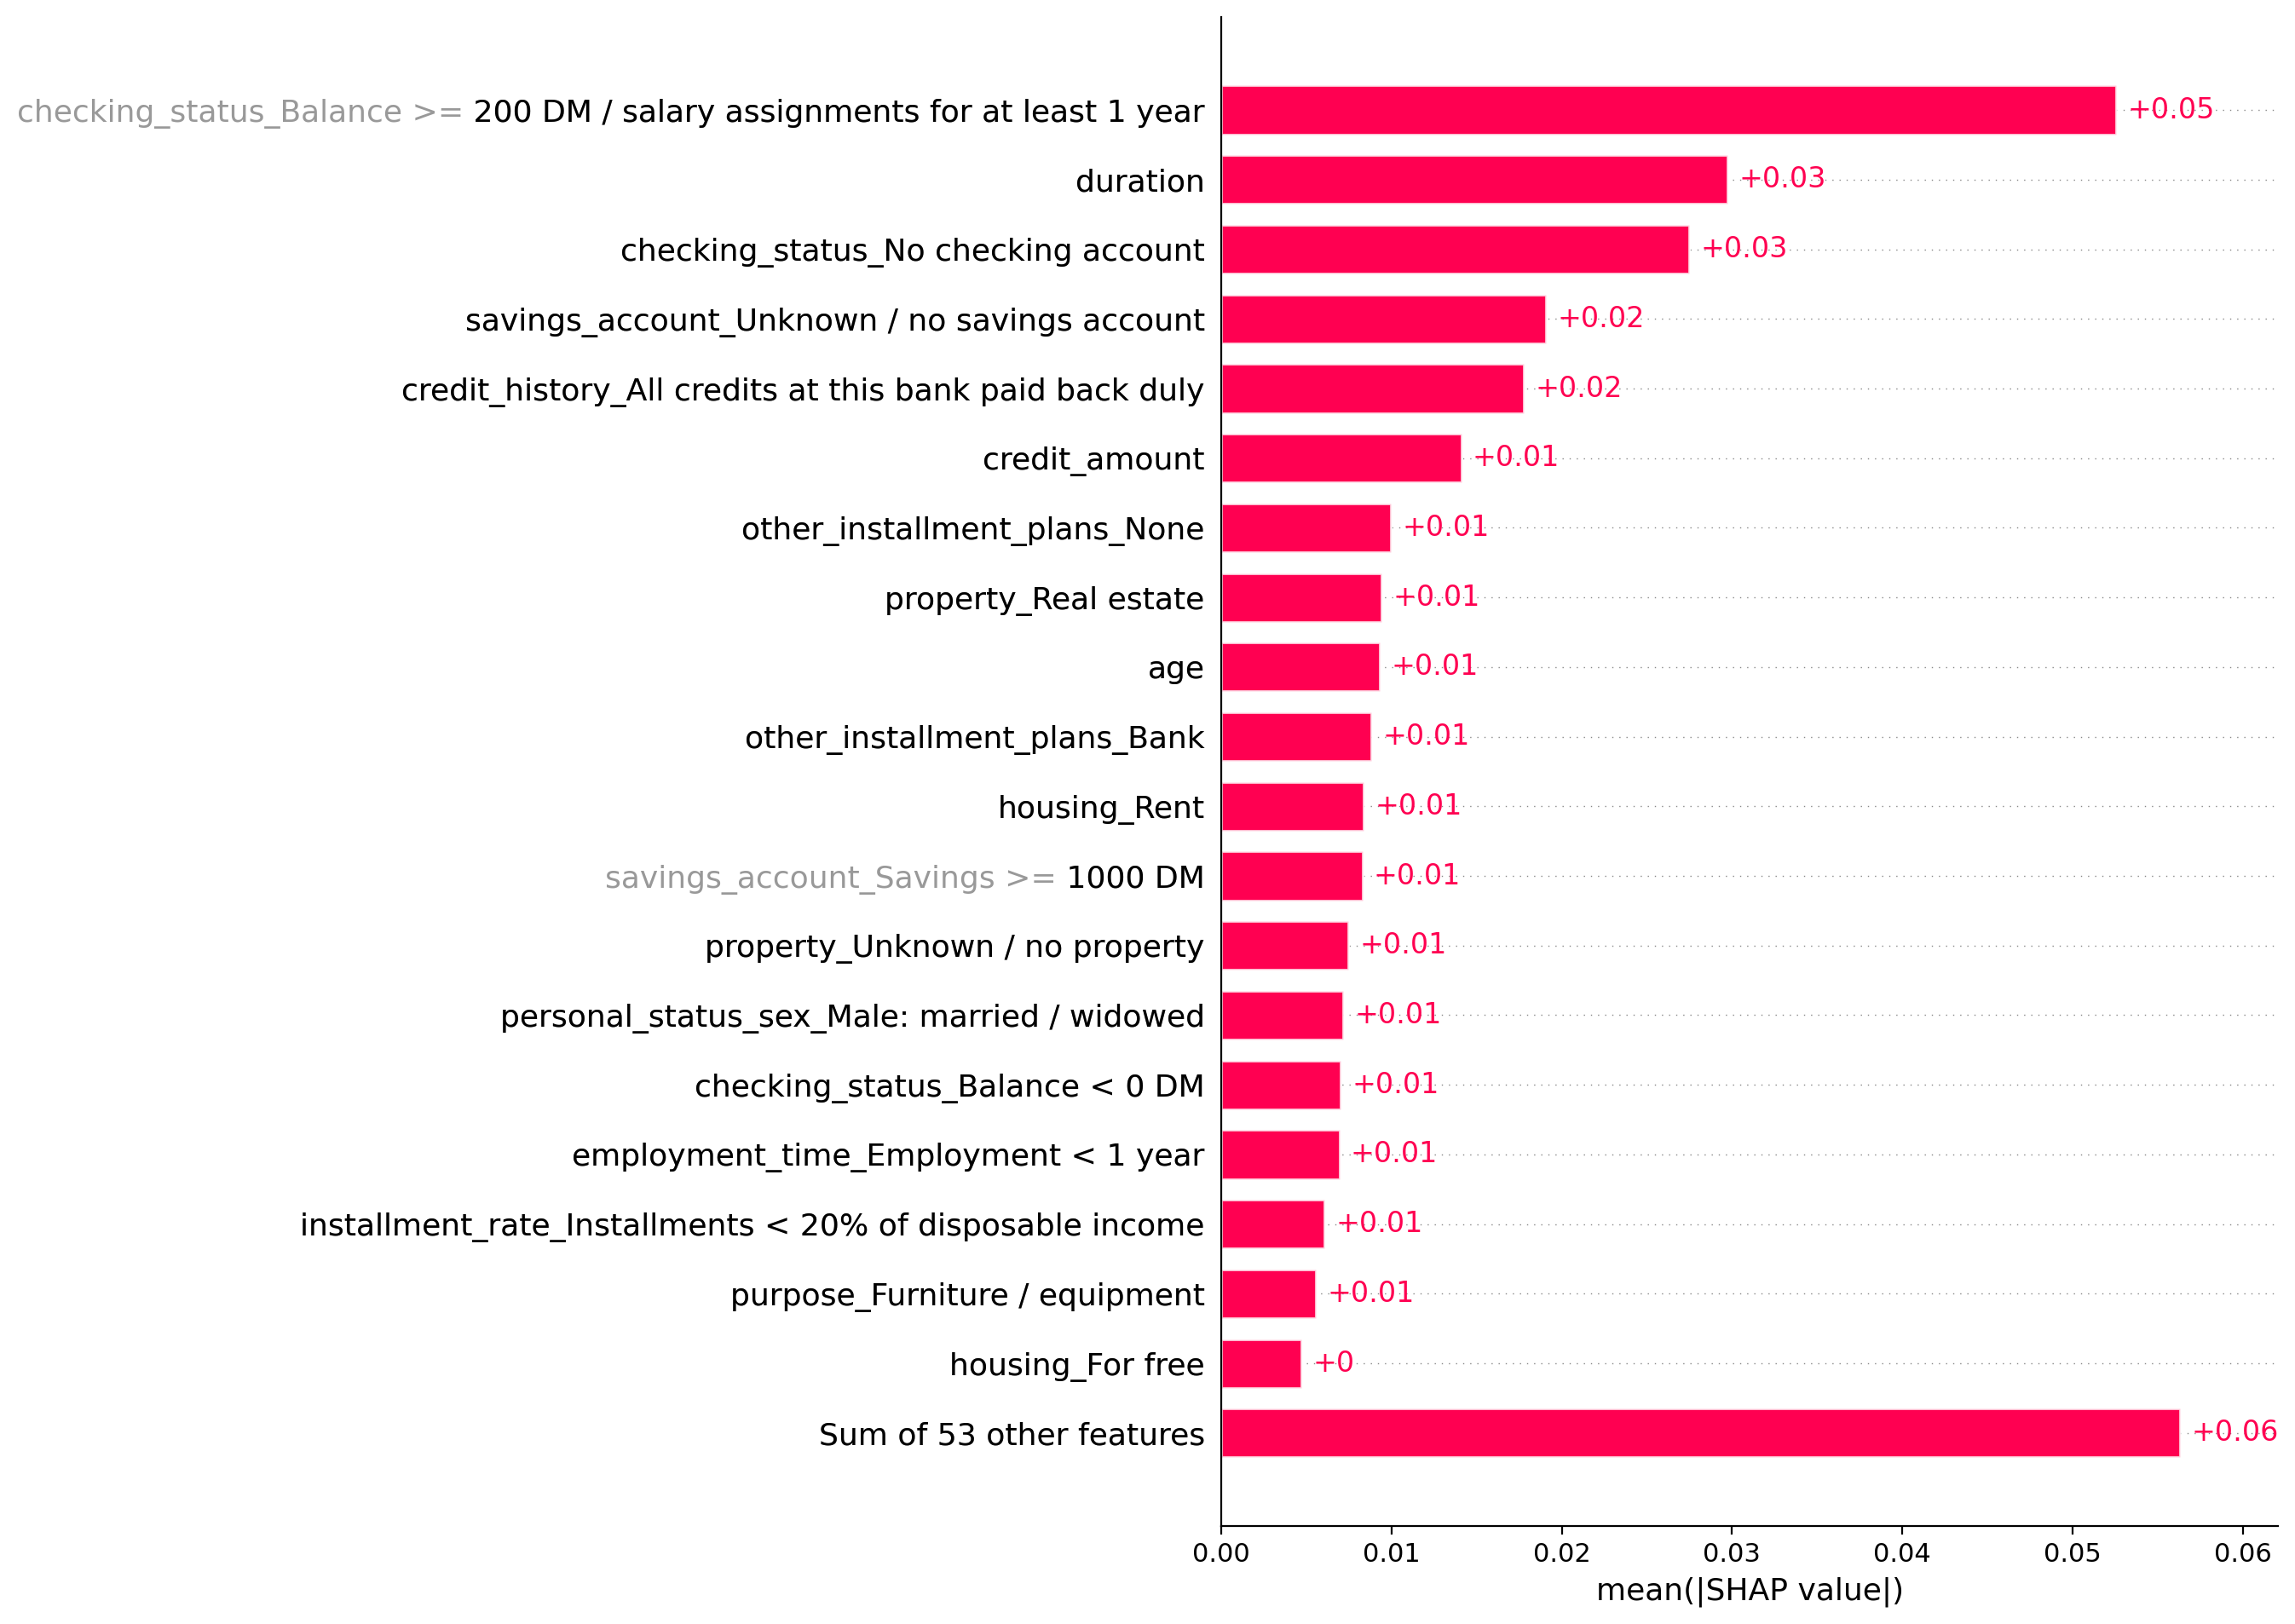

In [25]:
shap.plots.bar(shap_values, max_display=20)

In the beeswarm plot, points on the right increase predicted risk, while points on the left decrease it. Red represents higher feature values and blue represents lower values.

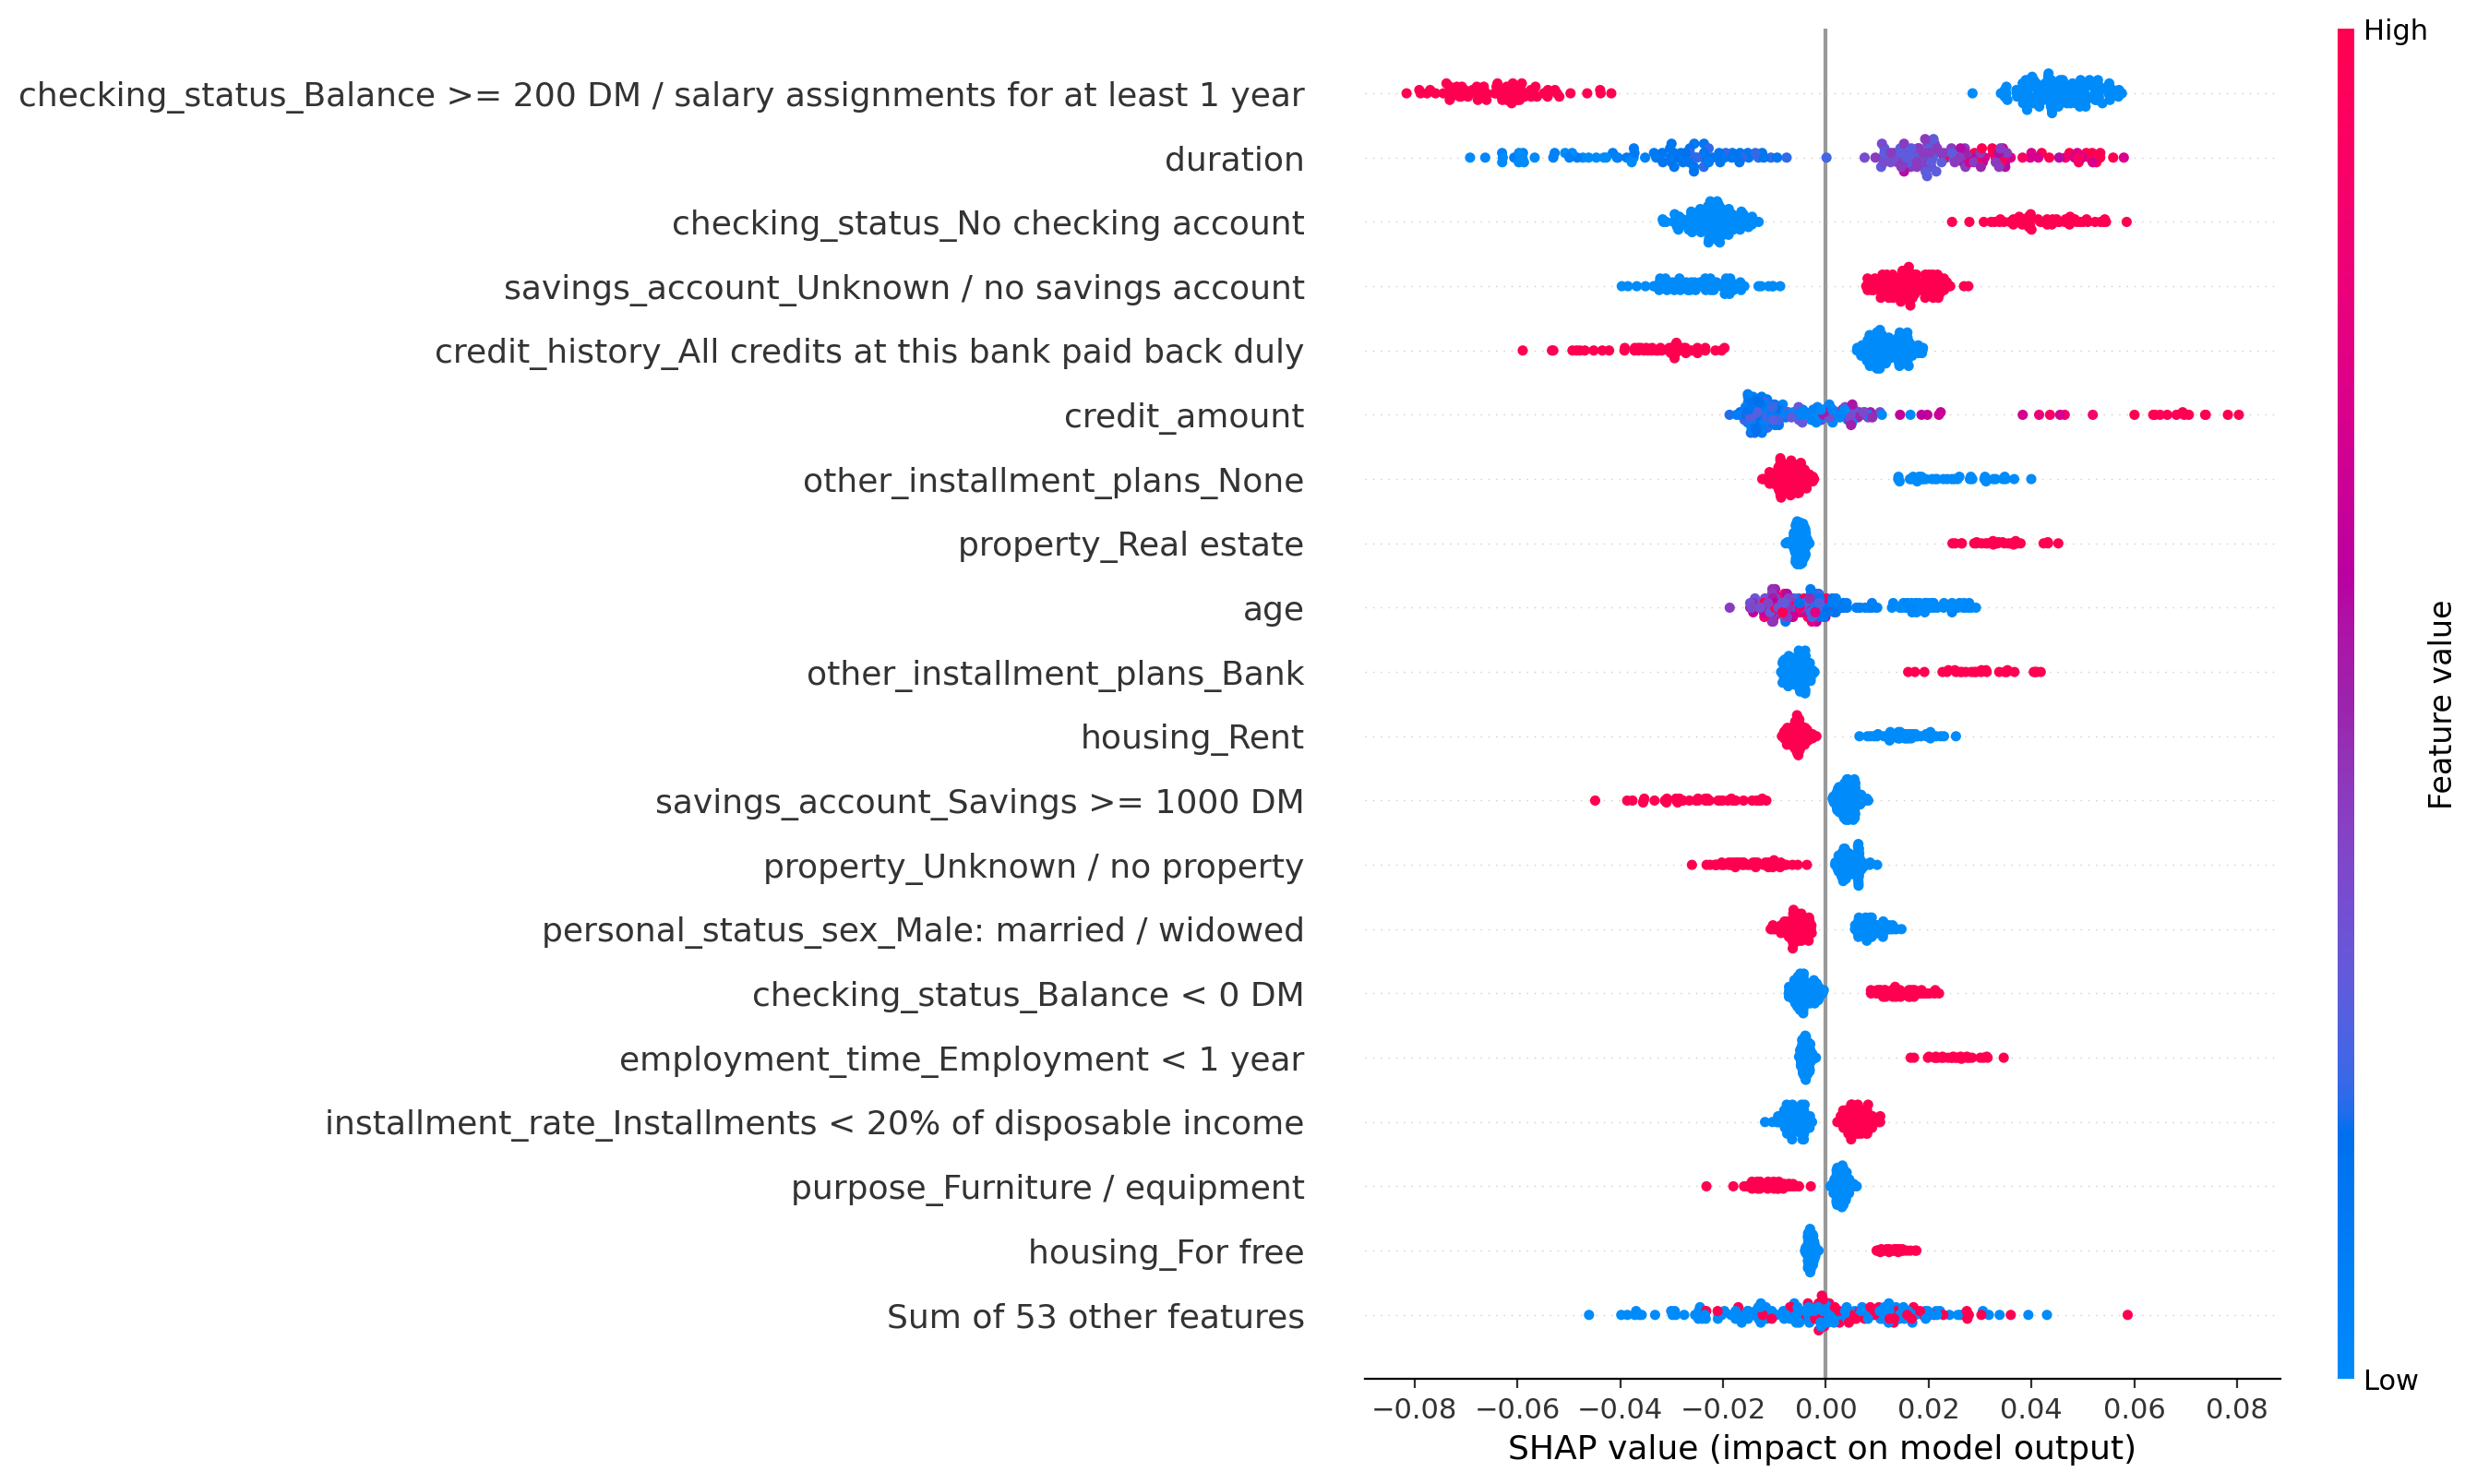

In [26]:
shap.plots.beeswarm(shap_values, max_display=20)

Some interesting observations:
- Having more balance will decrease the chance of beign a bad customer, which make sense!
- Short loan durations is related to a lower risk.
- Having “no checking account”  will increase the risk of being a bad customer (default).

#### 4.2 Local explanation
Here, I show an approved applicant and a high-risk rejected applicant who actual class is Bad.

Low-risk approved applicant
Applicant ID: 52
Actual class: Good
Predicted class: Good
P(Bad): 0.150
Cut-off: 0.227


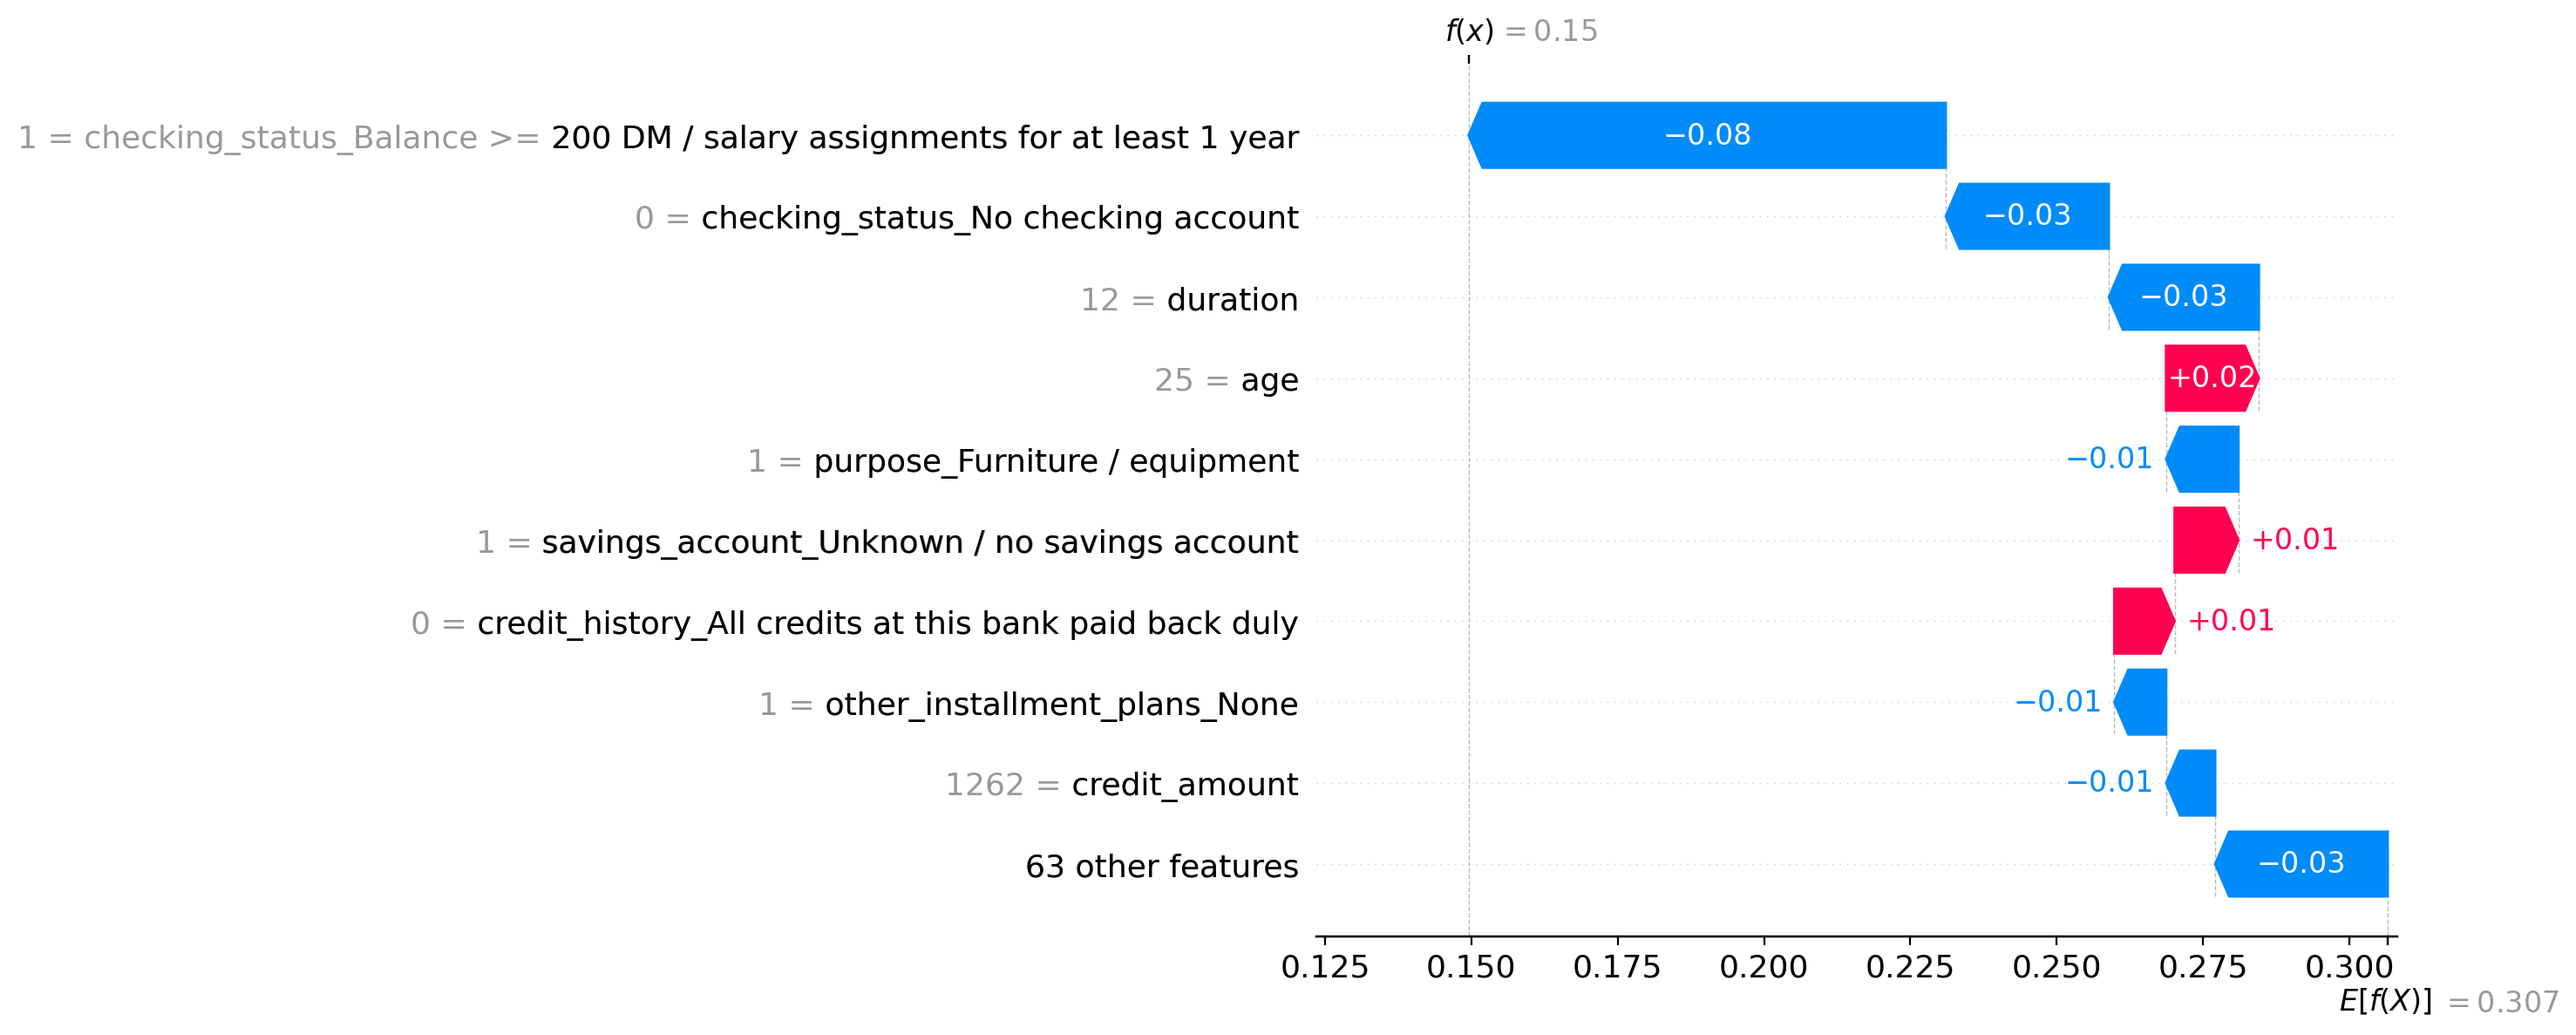

High-risk rejected applicant
Applicant ID: 11
Actual class: Bad
Predicted class: Bad
P(Bad): 0.586
Cut-off: 0.227


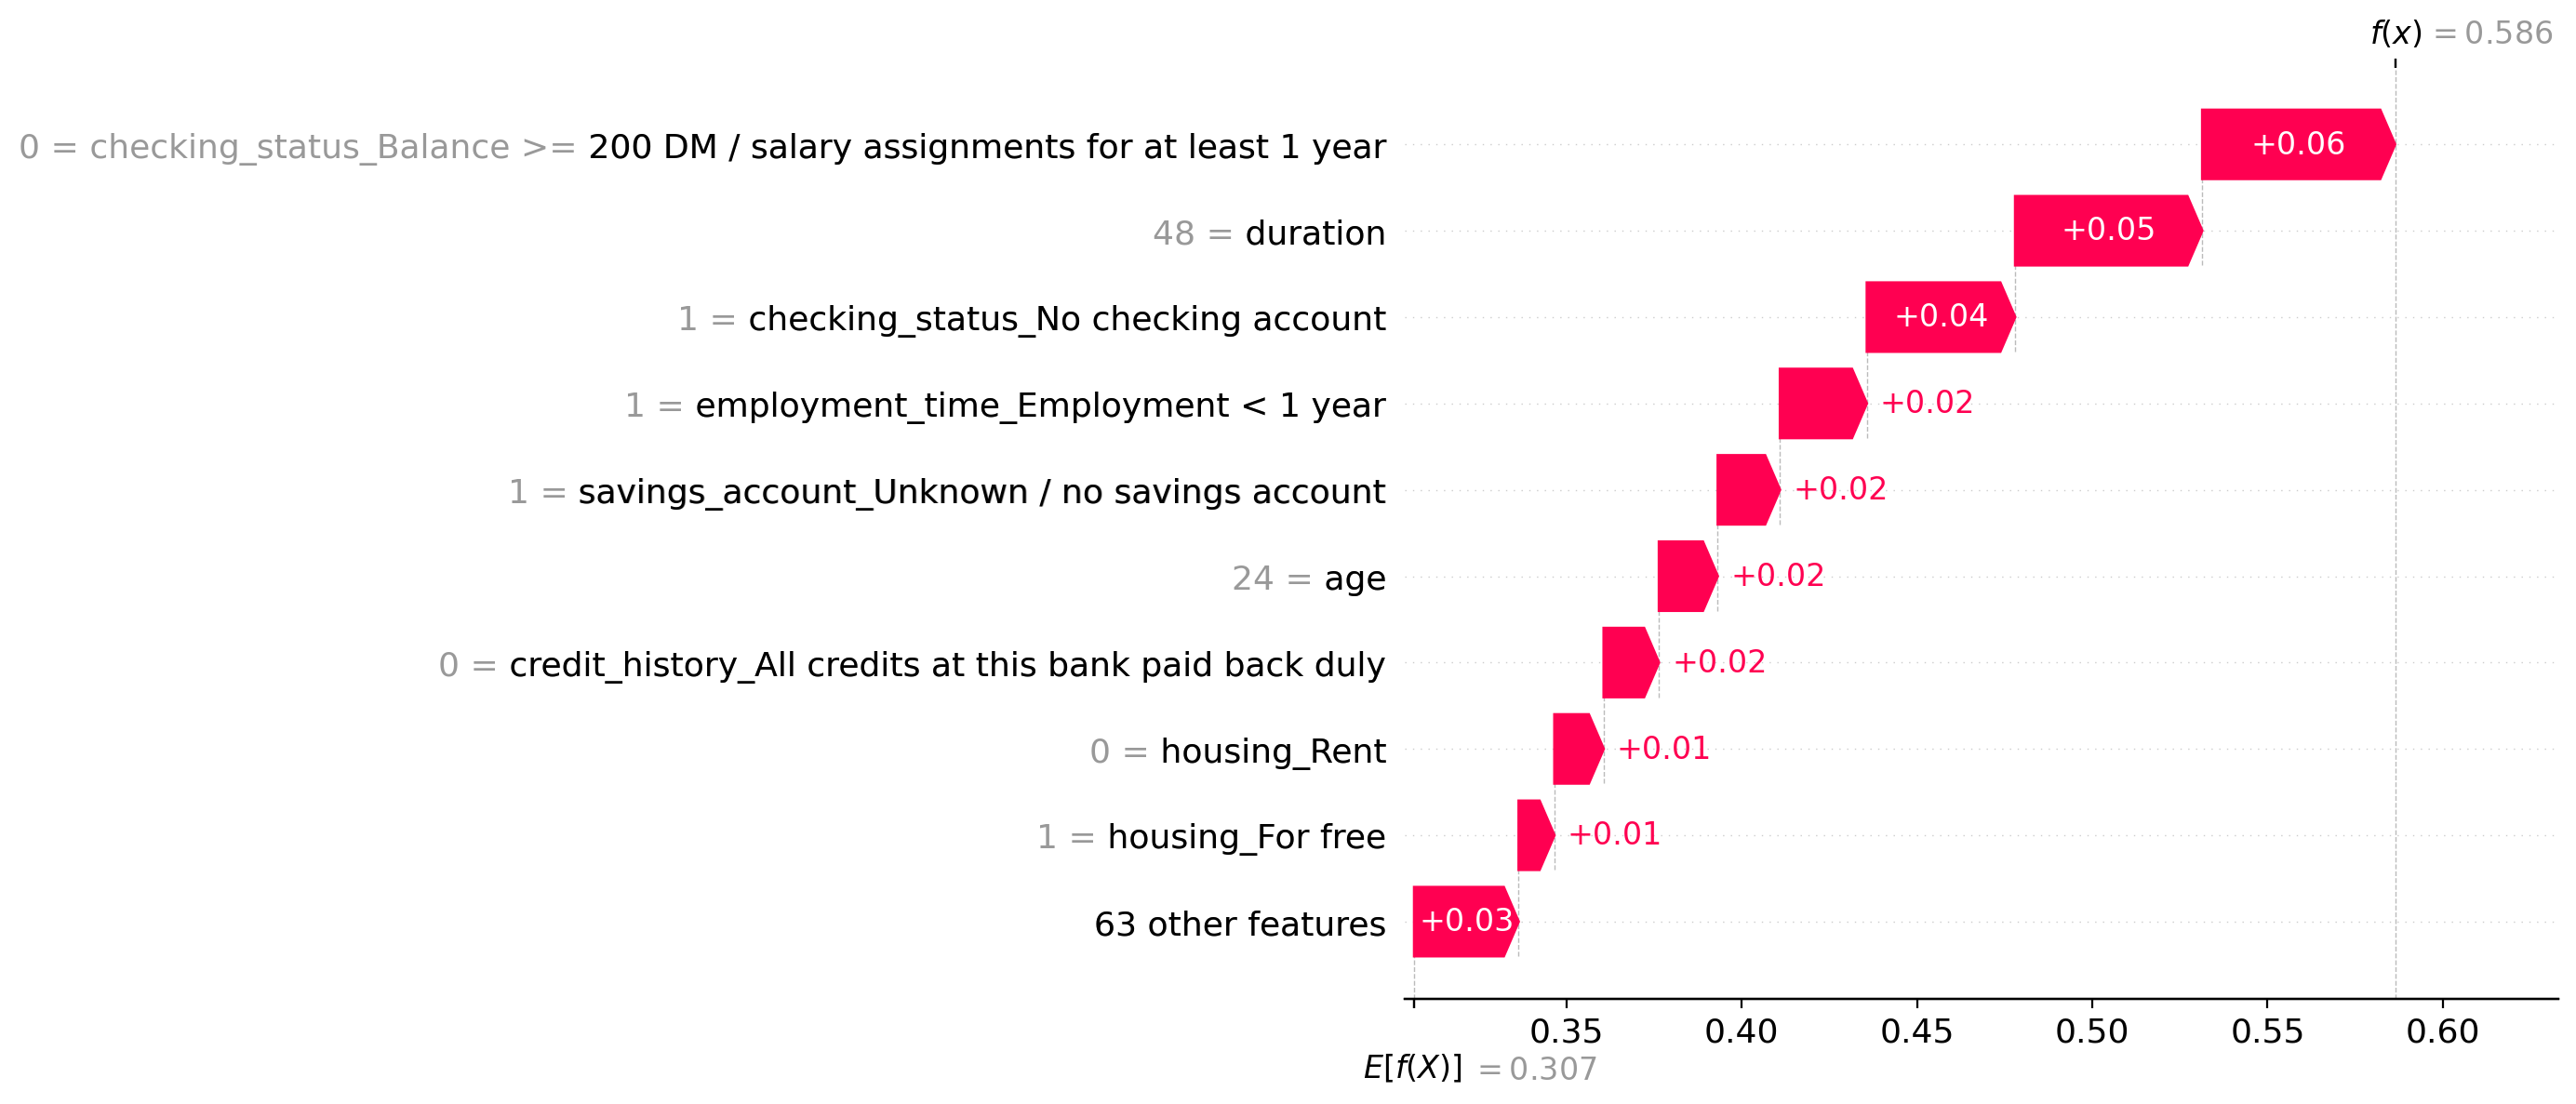

In [27]:
p_bad = final_model.predict_proba(X_test_encoded)[:, 1]

approved = np.flatnonzero(p_bad < final_threshold)
rejected = np.flatnonzero(p_bad >= final_threshold)

assert len(approved) > 0 and len(rejected) > 0, (
    "Both approved and rejected applicants are needed."
)

low_pos = X_test_encoded.index.get_loc(52)
high_pos = X_test_encoded.index.get_loc(11)

for title, pos in [
    ("Low-risk approved applicant", low_pos),
    ("High-risk rejected applicant", high_pos),
]:
    print(title)
    applicant_id = X_test_encoded.index[pos]
    actual_label = int(y_test.loc[applicant_id])
    predicted_label = int(p_bad[pos] >= final_threshold)
    print(f"Applicant ID: {applicant_id}")
    print(f"Actual class: {'Bad' if actual_label else 'Good'}")
    print(f"Predicted class: {'Bad' if predicted_label else 'Good'}")
    print(f"P(Bad): {p_bad[pos]:.3f}")
    print(f"Cut-off: {final_threshold:.3f}")

    shap.plots.waterfall(shap_values[pos], max_display=10)

    effects = pd.Series(
        shap_values[pos].values,
        index=feature_names,
    )

#### 4.3 LIME (optional)

/home/mehrdad/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


LIME local fit R²: 0.709


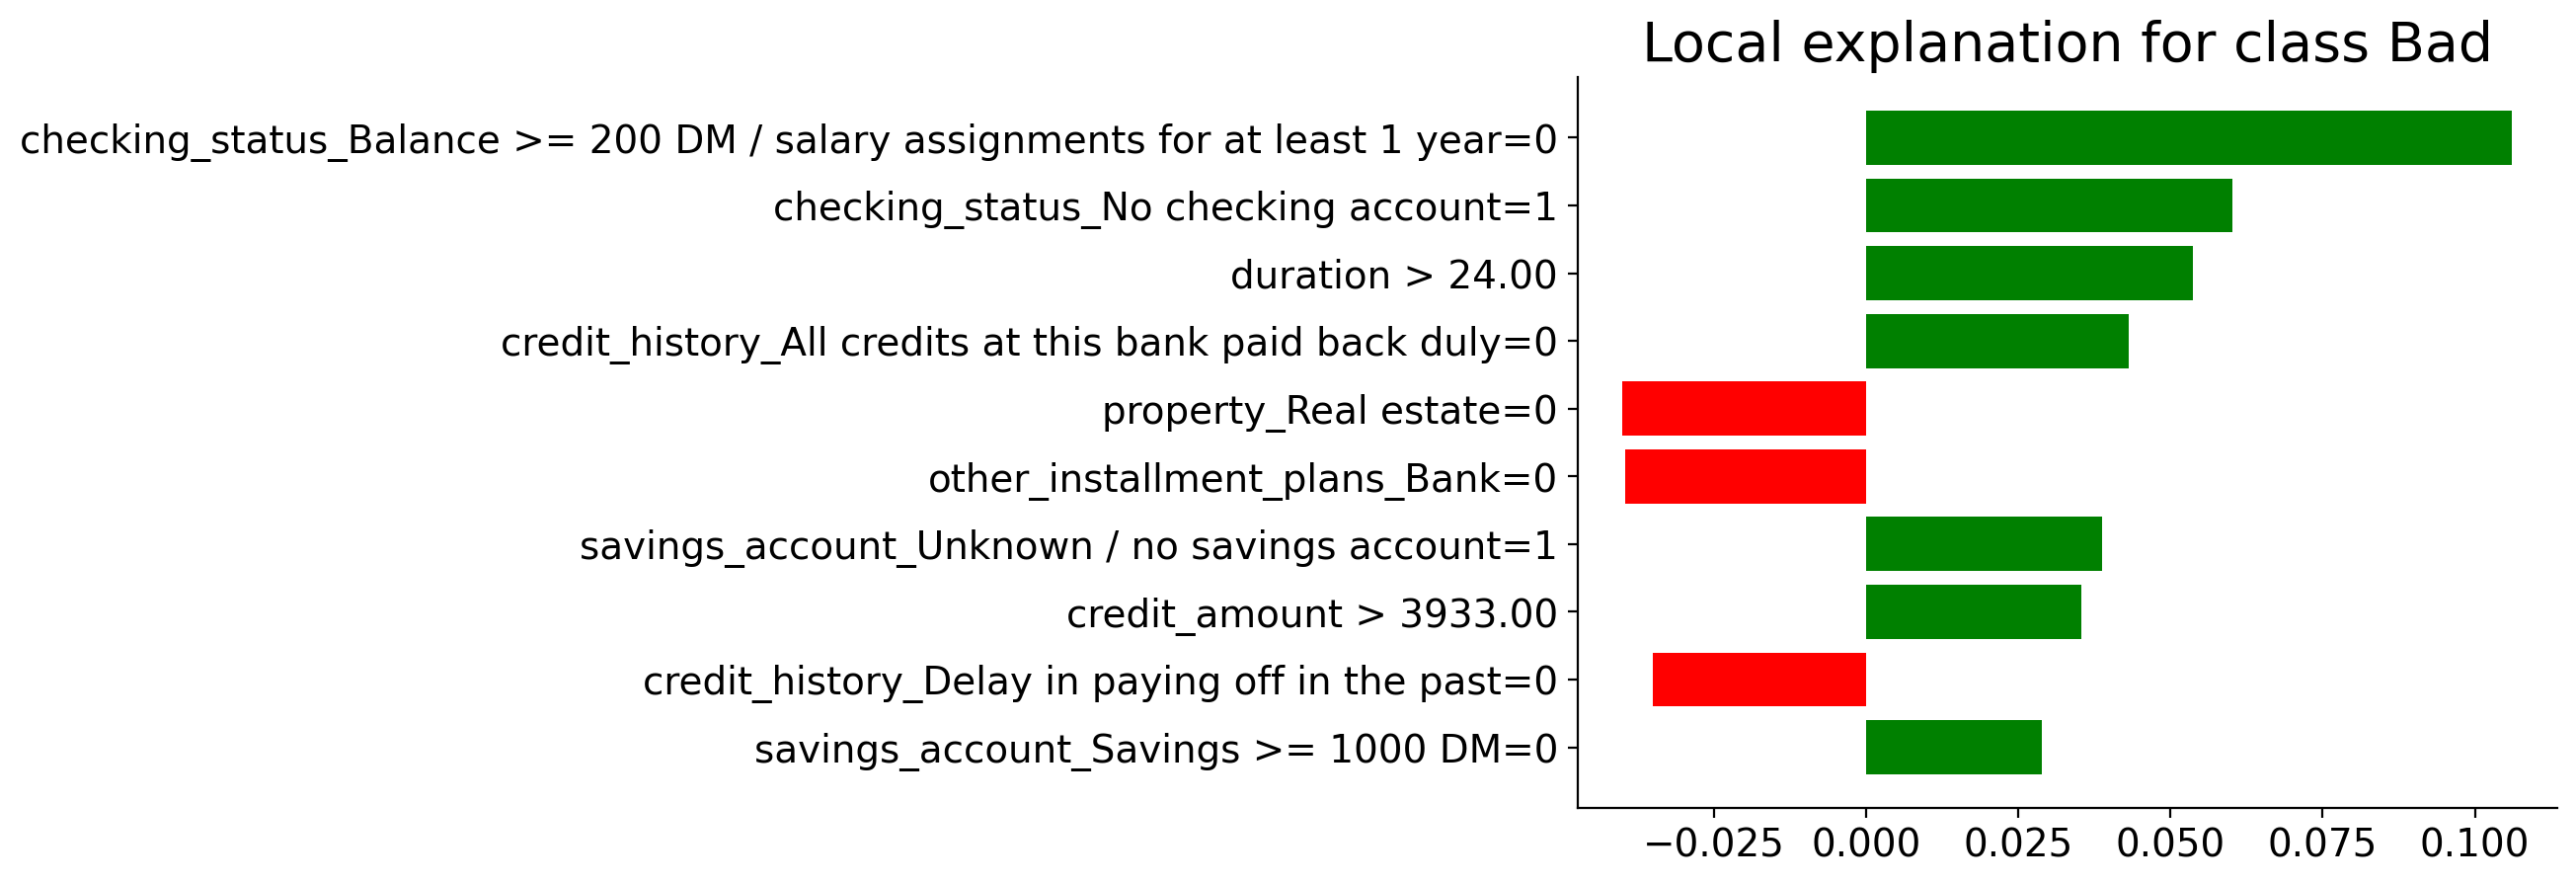

In [28]:
binary_features = [
    i for i, column in enumerate(feature_names)
    if X_train_encoded[column].isin([0, 1]).all()
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train_encoded.to_numpy(),
    feature_names=feature_names,
    class_names=["Good", "Bad"],
    categorical_features=binary_features,
    mode="classification",
    random_state=SEED,
)

lime_result = lime_explainer.explain_instance(
    X_test_encoded.iloc[high_pos].to_numpy(),
    xgb_model.predict_proba,
    labels=(1,),
    num_features=10,
)

lime_result.as_pyplot_figure(label=1)

print(f"LIME local fit R²: {lime_result.score:.3f}")

LIME and SHAP agree on several main factors. Both show that being outside the high-balance/salary-assignment category, having no checking account, and having a long loan duration increase the risk.

## 5. LLM as an explainer!!!

#### 5.1 Export SHAP values

In [29]:
applicant_id = 11
pos = X_test_encoded.index.get_loc(applicant_id)

probability = float(
    final_model.predict_proba(X_test_encoded.iloc[[pos]])[0, 1]
)

assert probability >= final_threshold, "This applicant was not rejected."

contributions = pd.DataFrame({
    "feature": feature_names,
    "value": X_test_encoded.iloc[pos].to_numpy(),
    "shap_contribution": shap_values[pos].values,
})

contributions = contributions.loc[
    contributions["shap_contribution"].abs().sort_values(
        ascending=False
    ).index
]

customer_data = {
    "decision": "Rejected",
    "predicted_bad_probability": probability,
    "rejection_threshold": float(final_threshold),
    "background_probability": float(shap_values[pos].base_values),
    "customer_features": json.loads(
        X_test_engineered.iloc[pos].to_json()
    ),
    "shap_contributions": json.loads(
        contributions.to_json(orient="records")
    ),
}

customer_json = json.dumps(customer_data, ensure_ascii=False, indent=2)

#### 5.2 System prompt

In [30]:
system_prompt = """
<TASK>
Write a respectful message in Persian for an ordinary customer
whose loan application was declined.
</TASK>

<INSTRUCTIONS>
1. Use only the provided customer data and SHAP contributions:
- positive values increase risk; negative values reduce it.
- For binary features, 1 means present and 0 means absent.
- Combine overlapping reasons instead of repeating them.

2. Use two sections:
- دلیل رد درخواست: Explain up to three main risk-increasing factors in everyday language.
- پیشنهاد برای ماه‌های آینده: Suggest two or three practical steps related to those factors. If suggesting a shorter loan term, mention that monthly payments may increase.

3. Do not mention models, AI, SHAP, scores, probabilities, thresholds, or technical terms. Do not invent financial problems or claim these factors prove the customer will miss payments.
4. Do not suggest changing age, sex, marital status, or nationality.
5. Do not guarantee approval after following the suggestions.
</INSTRUCTIONS>
"""

user_prompt = f"""
Explain this rejected application using the following model evidence:

{customer_json}
"""

#### 5.3 Calling OpenAI 

In [ ]:
client = OpenAI(
    api_key="aa-R2XQMJ2UX0Gw88eXueR8Cum0VJGM3rltcxWMN91ThzRvUote",
    base_url="https://api.avalai.ir/v1",
)

model_name = "gpt-6.1-sol"

response = client.chat.completions.create(
    model=model_name,
    messages=[
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ],
)

customer_explanation = response.choices[0].message.content
display(Markdown(customer_explanation))

Output Example:

##### دلیل رد درخواست:
متأسفیم که درخواست وام شما در این مرحله پذیرفته نشد. مهم‌ترین مواردی که در این تصمیم نقش داشتند عبارت‌اند از:

- **نداشتن حساب جاری:** در اطلاعات ارائه‌شده، حساب جاری برای شما ثبت نشده است.
- **دوره بازپرداخت طولانی:** مدت بازپرداخت درخواستی شما ۴۸ ماه است؛ این مدت طولانی از دلایل اصلی رد درخواست بود.
- **سابقه اشتغال کمتر از یک سال:** مدت اشتغال ثبت‌شده شما نیز در این تصمیم نقش داشت.

این موارد به معنای آن نیست که شما حتماً در پرداخت اقساط دچار مشکل خواهید شد.

##### پیشنهاد برای ماه‌های آینده:
- اگر امکانش را دارید، حساب جاری باز کنید و برای دریافت حقوق و پرداخت‌های معمول خود از آن استفاده کنید تا سابقه فعالیت حساب شکل بگیرد.
- دوره بازپرداخت کوتاه‌تری را بررسی کنید؛ **کوتاه‌تر شدن مدت وام ممکن است مبلغ قسط ماهانه را افزایش دهد**، بنابراین پیش از انتخاب، آن را با بودجه خود بسنجید.
- با طولانی‌تر شدن سابقه اشتغال، مدارک به‌روز مربوط به مدت کار و دریافتی خود را برای درخواست بعدی ارائه کنید.

انجام این اقدامات، تأیید درخواست بعدی را تضمین نمی‌کند.

## 6. Causality vs. Correlation

#### 6.1 Causes of risk or signs of risk?

- SHAP explains predictions of the model, not what causes a customer to be default! (**reference:** `Masterclass FinTech - XAI.pdf - Slide 30`)

- The SHAP bar plot shows average importance without direction, and the beeswarm plot shows direction. So, none of the plots proves causality.

- In last plots, `Balance >= 200 DM / salary assignments for at least 1 year` is the most important feature which has a great discriminitive power. Being in this category generally means lowers predicted risk.

#### 6.2 Is there any confounder?!

Yes! Income stability is a possible **confounder**: a factor that affects both the observed feature and the outcome.

For example, stable income may help a customer maintain a higher balance and also avoid missed payments.
Therefore, the separation of red and blue points for `checking status` feature does not prove that crossing `200 DM` causes lower risk. Also, temporarily adding money to an account may change its recorded status without improving long-term repayment ability!!!


So, overall ... in my opinion, **no variable is established as a direct cause of beign default by this notebook.**

#### 6.3 Any other interesting pattern?

Longer `duration`, `having no checking account`, and the `unknown / no savings account` features generally raise the risk too. A history of paying back all credits at this bank generally lowers it. Pay attention that these are just patterns learned by the model.

#### 6.4 What can a risk manager change?

Clearly, the risk manager should target changes that the bank can make and that could improve the customer's ability to repay.

- **Loan amount:** Offer an amount that fits verified income, essential expenses, and existing debts of each customer. In other words, we decide the loan amount based on the personal profile of each individual (i.e coustomizing the loan amount). This may reduce payment pressure, but it does not guarantee fewer defaults.

- **Interest rate:** Test whether lower borrowing costs improve repayment. Raising rates for customers predicted to be risky could instead make payments harder to meet. This dataset has no loan interest-rate feature.

#### 6.3 Operational decision-making

In short, we need to A/B test out policy (or idea) first!

- To evaluate a policy, the bank could randomly offer it to eligible customers and compare them with a control group over the same follow-up period. It should measure actual missed payments or defaults, affordability, and bank costs, rather than just a lower model score ... .

- Relying only on correlations can lead to wasted spending, unfair exclusions, or policies that improve scores without reducing real losses. 

- Changing the approval threshold only changes who receives the loan. It does not itself improve an individual customer's repayment ability. SHAP can suggest questions to investigate, but evidence about actual outcomes is needed before claiming that an intervention works.

-------------------------------------
# Thanks for your time! :)